# Record fixes and frozen rival predictors: demo of `eval.py`

**Artifact `art_mgek9PfVBNbh`** · iteration 5, Step 0 · CPU only, no model is run.

**Research context.** The project asks how "creativity" shows up inside an LLM. Asked to write a path-search function, does the model always produce BFS? Can a prompt ban, a plan-noise push along a random activation-space direction, a seed or a temperature move it to another algorithm? Earlier iterations ran Qwen3-8B (and a held-out Gemma-3-4B family) on 15 coding tasks. Every generated program was labelled with the algorithm it implements, using runtime traces, AST rules and a judge.

**What this artifact does.** `eval.py` re-derives every number that the iteration-4 report states about those runs from the raw rows of eight dependency artifacts. It writes each fix as an exact `old_text -> new_text` replacement: 35 entries, each marked `iteration-5 correction`. Every value carries a provenance tag: RE-DERIVED, READ, CARRIED or NOT_COMPUTABLE. When the record states a value, the value also gets a status against the record's tolerance:
- counts must match exactly;
- rates must agree within 0.005;
- correlations and log scores within 0.01;
- intervals within 0.02.

| section | what is re-derived |
|---|---|
| (0a) | held-out Gemma verdict: does push movability `E_t` predict which bans the model obeys? Balanced accuracy, Fisher exact test and Spearman, for each compliance measure |
| (0b) | where a push acts: which prefill positions change the algorithm (sites S0–S5, energy-matched S1E/S2E, paired flips with McNemar) |
| (0c) | landing forecasts on matched events: log scores of the push forecast vs association vs proximity |
| (0d) | executed but unreported results: PNPLAIN, hull deviation, Llama block, dose units, GPU hours |
| (0e) | per-direction distributions instead of best cells; split-half; signed progress; Table 147 depths |
| (0g), (0h) | exposure-class rule; Table 76 cross-reference (decoding of the thinking-on arm) |
| base | iteration-1 base-model compositions |

**What this notebook runs.** The record-correction stage of `eval.py` (`corrections()`). The code is copied cell by cell from `eval.py` and its helpers `src/io_util.py` and `src/stats_util.py`; the few notebook changes are marked `# notebook:`. In the original, `main()` then launches four separate scripts: the rival freeze, the rival scoring, a live quote check and a stdlib audit. It then assembles `eval_out.json`. Those scripts need further inputs and network access, so the notebook describes them but does not run them.

**Data.** `mini_demo_data.json` holds one dataset, `eval_inputs`, with 53 examples. Each example is one file that the stage opens, from 7 of the 8 dependency artifacts. The files are trimmed to the rows and fields `eval.py` reads, which cuts 77.7 MB of inputs down to 3.3 MB. With the original Monte Carlo sizes, the stage reproduces the artifact's published `corrections.json`, `results/corrections_metrics.json` and its 14 tables byte for byte on this bundle.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (the version the artifact pinned)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
# eval.py's import block, as in the original
from __future__ import annotations

import argparse
import csv
import json
import math
import re
import subprocess
import sys
import time
from collections import Counter, defaultdict
from pathlib import Path
from typing import Any

import numpy as np
from loguru import logger

# notebook additions: a namespace that stands in for `import stats_util as su`, and matplotlib for the results
from types import SimpleNamespace

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-5/evaluation-4/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(f"dataset '{data['datasets'][0]['dataset']}': {len(data['datasets'][0]['examples'])} input files "
      f"from {len(data['metadata']['dependencies'])} dependency artifacts")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
dataset 'eval_inputs': 53 input files from 7 dependency artifacts


## Configuration

The corrections stage trains nothing. Its cost lies in the Monte Carlo statistics, and three sizes control it:
- `N_BOOT`: bootstrap replicates behind the percentile intervals (balanced accuracy, Spearman, the PNPLAIN differences);
- `N_PERM`: random permutations behind each Spearman p-value;
- `N_PLACEBO`: placebo draws in (0a), which permute the movability `E_t` across tasks.

These sizes affect only intervals, permutation p-values and the placebo mean. Every point estimate comes out the same at any size: counts, rates, balanced accuracy, Fisher p, Spearman ρ, log scores. The original values are `N_BOOT = 10_000`, `N_PERM = 200_000` and `N_PLACEBO = 1000`, all seeded with `numpy.random.default_rng(20261021)`.

**This notebook uses the original values.** Timings measured in a fresh Colab-like environment:

| `N_BOOT` / `N_PERM` / `N_PLACEBO` | corrections stage | whole notebook (incl. installs, warm pip cache) | what changes |
|---|---|---|---|
| 10 / 100 / 10 | 1.6 s | 15 s | only the Monte Carlo quantities; 3 interval or p-value checks fall outside the record's tolerance |
| 1,000 / 20,000 / 100 | 2.6 s | 16 s | provenance counts already equal the record's |
| 10,000 / 200,000 / 1,000 (original) | 11.1 s | 24 s | every output byte-identical to the published artifact |

After changing a value, re-run the notebook from this cell. The defaults of the statistics functions are bound when their cell runs.

In [5]:
# Monte Carlo sizes (the src/stats_util.py constants and the (0a) placebo loop of eval.py)
N_BOOT = 10_000    # bootstrap replicates for percentile intervals   (original: 10_000)
N_PERM = 200_000   # permutation draws per Spearman p-value           (original: 200_000)
N_PLACEBO = 1000   # (0a) placebo draws with E_t permuted over tasks  (original: 1000)
SEED = 20261021    # numpy default_rng seed of every statistic (the original; keep it to reproduce the record)
# quick look: N_BOOT, N_PERM, N_PLACEBO = 10, 100, 10 runs the stage in about 2 s; point estimates stay the same

## Unpack the bundled inputs

`eval.py` reads every input through one class, `Inputs`. That class finds a dependency artifact at `<AII_DEPS_ROOT>/<artifact_id>` and opens files there by their relative path. This cell writes the 53 bundled files back in that layout, under `demo_outputs/deps/`, so the original reader runs unchanged. Row files are stored column-wise in the bundle. They are written back as one JSON object per line, as in the original files. For each file, the table shows how many rows were kept and the size of the original.

The stage's own outputs go to `demo_outputs/`, which stands in for the script's folder (`WS`). They are `corrections.json`, `results/`, `tables/`, `logs/` and `ids.json`.

To run on the complete dependency files instead, set the environment variable `AII_DEPS_ROOT` before the `io_util` cell runs. It must name a folder that holds the dependency artifacts, each in a folder named by its artifact id. As in the original, `AII_DEP_<artifact_id>` overrides a single one.

In [6]:
WS = Path("demo_outputs").resolve()   # notebook: stands in for the script's own folder (WS in eval.py)
DEMO_DEPS_ROOT = WS / "deps"          # notebook: the bundle, laid out as <AII_DEPS_ROOT>/<artifact_id>/<path>
WS.mkdir(parents=True, exist_ok=True)

print(f"{'dependency file (artifact_id:path)':68s} {'rows kept':>13s} {'original':>11s}")
for ex in data["datasets"][0]["examples"]:
    p = DEMO_DEPS_ROOT / ex["artifact_id"] / ex["path"]
    p.parent.mkdir(parents=True, exist_ok=True)
    if ex["format"] == "jsonl":  # column-wise in the bundle -> one JSON object per line, as in the original file
        p.write_text("".join(json.dumps(dict(zip(ex["columns"], v))) + "\n" for v in ex["rows"]))
        kept = f"{ex['n_rows_kept']} / {ex['n_rows_original']}"
    else:
        p.write_text(json.dumps(ex["content"]))
        kept = "trimmed" if ex["trimmed"] else "whole"
    print(f"{ex['source']:68s} {kept:>13s} {ex['original_bytes'] / 1e6:8.2f} MB")

dependency file (artifact_id:path)                                       rows kept    original
art_0ndRfWKBWclR:bench/R1_non_overlapping_intervals/spec.json                whole     0.00 MB
art_0ndRfWKBWclR:bench/R2_cycle_detection/spec.json                          whole     0.00 MB
art_0ndRfWKBWclR:bench/R3_topological_order/spec.json                        whole     0.00 MB
art_0ndRfWKBWclR:bench/R6_first_last_position/spec.json                      whole     0.00 MB
art_0ndRfWKBWclR:bench/T03_kth_smallest/spec.json                            whole     0.00 MB
art_0ndRfWKBWclR:bench/T04_substring_search/spec.json                        whole     0.00 MB
art_0ndRfWKBWclR:bench/T05_two_sum/spec.json                                 whole     0.00 MB
art_0ndRfWKBWclR:bench/T06_find_duplicate/spec.json                          whole     0.00 MB
art_0ndRfWKBWclR:bench/T08_fibonacci/spec.json                               whole     0.00 MB
art_0ndRfWKBWclR:bench/T10_connected_components/sp

art_k6nzFCDLOjQP:data/samples.jsonl                                   2400 / 10730    18.68 MB
art_k6nzFCDLOjQP:predictions/commit_preban.json                              whole     0.08 MB
art_k6nzFCDLOjQP:results/c3a.json                                            whole     0.01 MB
art_k6nzFCDLOjQP:results/bans.json                                           whole     0.01 MB
art_k6nzFCDLOjQP:results/pilot.json                                          whole     0.00 MB
art_k6nzFCDLOjQP:results/c1_prices.json                                      whole     0.04 MB
art_k6nzFCDLOjQP:results/posthoc_t2_relabel.json                             whole     0.00 MB
art_k6nzFCDLOjQP:results/c3b.json                                            whole     0.00 MB
art_Cx9JOh8soBw7:data/samples.jsonl                                    3968 / 4752    19.44 MB
art_Cx9JOh8soBw7:results/c1_site.json                                        whole     0.01 MB
art_Cx9JOh8soBw7:results/paired_flips.json        

art_Cx9JOh8soBw7:results/rederive_headlines.json                             whole     0.00 MB
art_SHaWv77P1XCI:results/c3b.json                                            whole     0.02 MB
art_SHaWv77P1XCI:results/escape.json                                         whole     0.04 MB
art_SHaWv77P1XCI:results/screen.json                                         whole     0.03 MB
art_SHaWv77P1XCI:inputs/exp13/results/c1_events.jsonl                      12 / 12     0.03 MB
art_SHaWv77P1XCI:inputs/exp16/results/c1_events.jsonl                      11 / 11     0.01 MB
art_SHaWv77P1XCI:data/labels.jsonl                                   10520 / 13500    13.03 MB
art_mWn-MQEnNelg:data/samples.jsonl                                   1900 / 10100    14.56 MB


art_mWn-MQEnNelg:results/plain_vs_twin.json                                  whole     0.01 MB
art_mWn-MQEnNelg:results/deviations.jsonl                                  16 / 16     0.01 MB
art_mWn-MQEnNelg:results/prices.json                                         whole     0.07 MB
art_SHaWv77P1XCI:results/units.json                                          whole     0.01 MB
art_Cx9JOh8soBw7:results/units_summary.json                                  whole     0.01 MB
art_SHaWv77P1XCI:results/deviations.json                                     whole     0.00 MB
art_k6nzFCDLOjQP:results/qwen_ratio.json                                     whole     0.01 MB
art_Yu6GN6pLxW8f:results/unit_sensitivity.json                               whole     0.00 MB
art_Yu6GN6pLxW8f:results/gpu_hours.json                                      whole     0.00 MB
art_Yu6GN6pLxW8f:results/c1seed.json                                         whole     0.05 MB
art_SHaWv77P1XCI:results/rederive_extra.json      

art_Yu6GN6pLxW8f:results/thinking.json                                       whole     0.01 MB
art_Yu6GN6pLxW8f:data/raw_thinking.jsonl                                 140 / 140     6.68 MB
art_HF8nK8B_Lqyy:runs/labelled_base_chat__baseline.jsonl                 600 / 600     2.45 MB
art_HF8nK8B_Lqyy:runs/labelled_base_tf__baseline.jsonl                   600 / 600     1.93 MB


## `src/io_util.py`: dependency paths, input manifest, provenance records

This cell is a verbatim copy of the helper module that `eval.py` imports (`DEPS, NAMES, TASKS, Inputs, as_bool, r, val`). The only change: dependencies default to the unpacked bundle.

- `DEP_IDS` maps the short names used in the code (`exp19` … `exp23`, `exp5`, `bench`) to the artifact ids.
- `Inputs` opens every dependency file and records its sha256 in a manifest. In this demo the hashes are those of the trimmed copies; `original_sha256` in the bundle identifies each original file.
- `val()` builds one provenance record per value. It compares the value with the record's value under the tolerance of its kind (`TOL`) and sets the status:
  - **MATCH**: within tolerance;
  - **CORRECTED**: outside tolerance;
  - **NEW**: the record states no value;
  - **CARRIED**: taken from the record, not re-derived;
  - **NOT_COMPUTABLE**.

In [7]:
"""Dependency paths, hashed input manifest and provenance records (plan PART 0.1-0.4)."""

from __future__ import annotations

import hashlib
import json
import os
import re
from pathlib import Path
from typing import Any, Callable

# WS = Path(__file__).resolve().parent.parent   (notebook: WS is the demo output folder set in the unpack cell)
# Dependencies are read in place, read-only.  In the published repository each dependency artifact is a sibling folder
# of this one, named by its artifact id: <AII_DEPS_ROOT>/<artifact_id>, with AII_DEPS_ROOT defaulting to the parent
# folder of this workspace.  A single dependency can be pointed elsewhere with AII_DEP_<artifact_id> (non-alphanumeric
# characters of the id replaced by '_', e.g. AII_DEP_art_mWn_MQEnNelg).
DEPS_ROOT = Path(os.environ.get("AII_DEPS_ROOT", str(DEMO_DEPS_ROOT)))  # notebook: default = the unpacked bundle
DEP_IDS: dict[str, str] = {
    "exp23": "art_k6nzFCDLOjQP",  # held-out family (gemma-3-4b-it), iteration 4
    "exp20": "art_Cx9JOh8soBw7",  # site experiment, iteration 4
    "exp22": "art_SHaWv77P1XCI",  # plan subspace / escape fractions, iteration 4
    "exp19": "art_mWn-MQEnNelg",  # plan noise knob table, iteration 4
    "exp21": "art_Yu6GN6pLxW8f",  # same-seed temperature vs plan noise, iteration 4
    "exp5": "art_HF8nK8B_Lqyy",   # iteration-1 base-model data (run 4VFKidE1bxPG)
    "bench": "art_0ndRfWKBWclR",  # iteration-2 coding bench
    "src": "art_j3Rm_lr2nzR6",    # iteration-1 source data (run 4VFKidE1bxPG)
}


def dep_dir(art_id: str) -> Path:
    return Path(os.environ.get("AII_DEP_" + re.sub(r"\W", "_", art_id), str(DEPS_ROOT / art_id)))


DEPS: dict[str, tuple[str, Path]] = {k: (a, dep_dir(a)) for k, a in DEP_IDS.items()}
TOL = {"count": 0.0, "rate": 0.005, "stat": 0.01, "interval": 0.02}
TASKS = ["T1", "T2", "T03", "T04", "T05", "T06", "T08", "T10", "T11", "T13", "T14", "R1", "R2", "R3", "R6"]
NAMES = {"T1": "grid path", "T2": "weighted shortest path", "T03": "kth smallest", "T04": "substring search",
         "T05": "two sum", "T06": "find duplicate", "T08": "Fibonacci", "T10": "connected components",
         "T11": "longest increasing subsequence", "T13": "merge intervals", "T14": "top-k frequent",
         "R1": "non-overlapping intervals", "R2": "cycle detection", "R3": "topological order",
         "R6": "first and last position"}


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with p.open("rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def as_bool(v: Any) -> bool:
    return v is True or v == "True" or v == "true" or v == 1


class Inputs:
    """Every dependency file read goes through here: path resolution, sha256 manifest, a 'source' string."""

    def __init__(self, log: Callable[[str], None] | None = None, forbidden: tuple[str, ...] = ()):
        self.manifest: dict[str, dict[str, Any]] = {}
        self.log = log
        self.forbidden = forbidden

    def path(self, dep: str, rel: str) -> Path:
        art, root = DEPS[dep]
        p = root / rel
        src = f"{art}:{rel}"
        for f in self.forbidden:
            if f in src:
                raise PermissionError(f"forbidden input for this script: {src}")
        if src not in self.manifest:
            if not p.exists():
                self.manifest[src] = {"exists": False, "abs_dep": dep}
                raise FileNotFoundError(src)
            self.manifest[src] = {"exists": True, "sha256": sha256_file(p), "bytes": p.stat().st_size, "dep": dep}
            if self.log:
                self.log(f"open {src}")
        return p

    def src(self, dep: str, rel: str) -> str:
        return f"{DEPS[dep][0]}:{rel}"

    def json(self, dep: str, rel: str) -> Any:
        return json.loads(self.path(dep, rel).read_text())

    def jsonl(self, dep: str, rel: str, must_contain: str | None = None) -> list[dict[str, Any]]:
        out = []
        with self.path(dep, rel).open() as fh:
            for ln in fh:
                if not ln.strip() or (must_contain is not None and must_contain not in ln):
                    continue
                out.append(json.loads(ln))
        return out


def close(a: float | None, b: float | None, kind: str) -> bool | None:
    if a is None or b is None:
        return None
    return abs(float(a) - float(b)) <= TOL[kind] + 1e-12


def val(name: str, value: Any, tag: str, source: str, record: Any = None, kind: str = "stat",
        note: str | None = None) -> dict[str, Any]:
    """One provenance record.  status: MATCH / CORRECTED (outside tolerance) / NEW (no record value) / CARRIED /
    NOT_COMPUTABLE."""
    if tag == "CARRIED":
        status = "CARRIED"
    elif tag == "NOT_COMPUTABLE" or value is None:
        status = "NOT_COMPUTABLE"
    elif record is None:
        status = "NEW"
    elif isinstance(value, (int, float)) and isinstance(record, (int, float)):
        status = "MATCH" if close(value, record, kind) else "CORRECTED"
    elif isinstance(value, (list, tuple)) and isinstance(record, (list, tuple)) and len(value) == len(record) and \
            all(isinstance(x, (int, float)) for x in list(value) + list(record)):
        status = "MATCH" if all(close(a, b, kind) for a, b in zip(value, record)) else "CORRECTED"
    else:
        status = "MATCH" if value == record else "CORRECTED"
    out = {"name": name, "record_value": record, "value": value, "tag": tag, "source": source, "status": status,
           "tolerance": kind}
    if note:
        out["note"] = note
    return out


def r(x: Any, nd: int = 3) -> Any:
    if isinstance(x, float):
        return round(x, nd)
    if isinstance(x, list):
        return [r(v, nd) for v in x]
    if isinstance(x, dict):
        return {k: r(v, nd) for k, v in x.items()}
    return x

## `src/stats_util.py`: statistics

This is the artifact's shared statistics module. It is copied verbatim except for three constants, which now come from the config cell. It provides:
- **exact rarefied Hill-1 diversity**: the expected exp-Shannon diversity of a 25-program subsample drawn without replacement, by full enumeration;
- **Spearman tests**: the correlation, a Monte Carlo permutation p-value and its Monte Carlo SE;
- **other correlation and interval tools**: Kendall τ-b, bootstrap intervals, partial Spearman;
- **exact AUC** with a rank-sum p-value by enumeration, and the **Holm** adjustment;
- **classification tests**: balanced accuracy, Fisher's exact test and the exact McNemar test.

`eval.py` calls these functions as `su.<name>`, so the cell ends by collecting them into a namespace `su`.

In [8]:
"""Statistics shared by eval.py, rivals/compute_rivals.py and rivals/score_rivals.py (NOT by audit/rederive.py,
which re-implements everything with the standard library only).

Conventions (plan PART 0.5-0.6): numpy default_rng(20261021); bootstrap 10,000 replicates (percentile intervals);
permutation tests 200,000 Monte Carlo draws with the Monte Carlo SE; exact enumeration where feasible.
"""

from __future__ import annotations

import itertools
import math
from collections import Counter
from typing import Any, Iterable, Sequence

import numpy as np
from scipy import stats

# SEED = 20261021
# N_BOOT = 10_000
# N_PERM = 200_000
# notebook: SEED, N_BOOT and N_PERM are set in the config cell (the values above are the originals)
NOT_ALT = ("other", "invalid", "disputed", "unknown", "unlabelled", None, "None", "")


# ------------------------------------------------------------------------------------------------ diversity
def hill1_raw(counts: dict[str, int]) -> float | None:
    c = np.array([v for v in counts.values() if v > 0], float)
    if c.sum() <= 0:
        return None
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def _compositions(caps: list[int], total: int):
    """All vectors k with 0 <= k_i <= caps_i and sum k = total."""
    if len(caps) == 1:
        if total <= caps[0]:
            yield (total,)
        return
    rest = sum(caps[1:])
    for k in range(max(0, total - rest), min(caps[0], total) + 1):
        for tail in _compositions(caps[1:], total - k):
            yield (k,) + tail


def hill1_rarefied(counts: dict[str, int], depth: int = 25) -> dict[str, Any]:
    """Exact expected Hill-1 (exp Shannon) of a subsample of size `depth` drawn WITHOUT replacement (multivariate
    hypergeometric enumeration; the run's Monte-Carlo estimator has the same expectation).  Depth falls back to the
    number of programs when fewer are available (flagged)."""
    cs = [int(v) for v in counts.values() if v > 0]
    n = sum(cs)
    if n == 0:
        return {"hill": None, "depth": 0, "flag": "no programs"}
    d = min(depth, n)
    flag = None if d == depth else f"own depth {d}"
    if len(cs) == 1:
        return {"hill": 1.0, "depth": d, "flag": flag}
    log_denom = math.lgamma(n + 1) - math.lgamma(d + 1) - math.lgamma(n - d + 1)
    lg = [[math.lgamma(c + 1) - math.lgamma(k + 1) - math.lgamma(c - k + 1) for k in range(c + 1)] for c in cs]
    tot = 0.0
    for comp in _compositions(cs, d):
        lp = sum(lg[i][k] for i, k in enumerate(comp)) - log_denom
        h = -sum((k / d) * math.log(k / d) for k in comp if k > 0)
        tot += math.exp(lp) * math.exp(h)
    return {"hill": float(tot), "depth": d, "flag": flag}


# ------------------------------------------------------------------------------------------------ correlation
def ranks(x: Sequence[float]) -> np.ndarray:
    return stats.rankdata(np.asarray(x, float), method="average")


def spearman(x: Sequence[float], y: Sequence[float]) -> float | None:
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 3 or np.std(x) == 0 or np.std(y) == 0:
        return None
    return float(np.corrcoef(ranks(x), ranks(y))[0, 1])


def perm_spearman(x: Sequence[float], y: Sequence[float], n_perm: int = N_PERM, seed: int = SEED,
                  chunk: int = 20_000) -> dict[str, Any]:
    x, y = np.asarray(x, float), np.asarray(y, float)
    rho = spearman(x, y)
    if rho is None:
        return {"rho": None, "p_two_sided": None, "p_one_sided_ge": None, "mc_se_two_sided": None, "n": len(x),
                "n_perm": n_perm, "note": "constant input or n < 3"}
    rx, ry = ranks(x), ranks(y)
    rx = (rx - rx.mean()) / rx.std()
    ry = (ry - ry.mean()) / ry.std()
    rng = np.random.default_rng(seed)
    ge_abs = ge = 0
    done = 0
    while done < n_perm:
        m = min(chunk, n_perm - done)
        perm = np.argsort(rng.random((m, len(x))), axis=1)
        rp = (rx[None, :] * ry[perm]).mean(1)
        ge_abs += int(np.sum(np.abs(rp) >= abs(rho) - 1e-12))
        ge += int(np.sum(rp >= rho - 1e-12))
        done += m
    p2 = (ge_abs + 1) / (n_perm + 1)
    p1 = (ge + 1) / (n_perm + 1)
    return {"rho": rho, "p_two_sided": p2, "p_one_sided_ge": p1, "mc_se_two_sided": math.sqrt(p2 * (1 - p2) / n_perm),
            "n": len(x), "n_perm": n_perm}


def kendall_b(x: Sequence[float], y: Sequence[float]) -> float | None:
    if len(set(x)) < 2 or len(set(y)) < 2:
        return None
    return float(stats.kendalltau(x, y, variant="b").statistic)


def boot_spearman(x: Sequence[float], y: Sequence[float], n_boot: int = N_BOOT, seed: int = SEED) -> dict[str, Any]:
    x, y = np.asarray(x, float), np.asarray(y, float)
    rng = np.random.default_rng(seed + 7)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(x), len(x))
        r = spearman(x[idx], y[idx])
        if r is not None:
            vals.append(r)
    if not vals:
        return {"ci95": None, "n_valid": 0}
    return {"ci95": [float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))], "n_valid": len(vals)}


def partial_spearman(x: Sequence[float], y: Sequence[float], z: np.ndarray | Sequence[float]) -> float | None:
    """Spearman correlation of x and y after removing (linear in ranks) one or more covariates z."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    z = np.asarray(z, float)
    if z.ndim == 1:
        z = z[:, None]
    if len(x) < 4 or np.std(x) == 0 or np.std(y) == 0:
        return None
    rz = np.column_stack([ranks(z[:, j]) for j in range(z.shape[1]) if np.std(z[:, j]) > 0] or [np.zeros(len(x))])
    X = np.column_stack([np.ones(len(x)), rz])
    rx, ry = ranks(x), ranks(y)
    ex = rx - X @ np.linalg.lstsq(X, rx, rcond=None)[0]
    ey = ry - X @ np.linalg.lstsq(X, ry, rcond=None)[0]
    if np.std(ex) < 1e-12 or np.std(ey) < 1e-12:
        return None
    return float(np.corrcoef(ex, ey)[0, 1])


def auc_exact(scores: Sequence[float], labels: Sequence[int]) -> dict[str, Any]:
    """AUC = P(score_pos > score_neg) + 0.5 P(tie); exact two-sided rank-sum p by enumerating every assignment of
    the observed number of positives to the units (C(15,5) = 3,003 splits for the full panel)."""
    s = np.asarray(scores, float)
    lab = np.asarray(labels, int)
    npos, n = int(lab.sum()), len(lab)
    if npos == 0 or npos == n:
        return {"auc": None, "p_exact_two_sided": None, "n_splits": 0}

    def auc_of(pos_idx: tuple[int, ...]) -> float:
        m = np.zeros(n, bool)
        m[list(pos_idx)] = True
        a, b = s[m], s[~m]
        gt = (a[:, None] > b[None, :]).sum()
        eq = (a[:, None] == b[None, :]).sum()
        return float((gt + 0.5 * eq) / (len(a) * len(b)))

    obs = auc_of(tuple(np.flatnonzero(lab)))
    null = [auc_of(c) for c in itertools.combinations(range(n), npos)]
    dev = abs(obs - 0.5)
    p = float(np.mean([abs(v - 0.5) >= dev - 1e-12 for v in null]))
    return {"auc": obs, "p_exact_two_sided": p, "n_splits": len(null)}


def holm(ps: dict[str, float | None]) -> dict[str, float | None]:
    items = sorted([(k, v) for k, v in ps.items() if v is not None], key=lambda kv: kv[1])
    m = len(items)
    out: dict[str, float | None] = {k: None for k in ps}
    run = 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out


# ------------------------------------------------------------------------------------------------ classification
def balanced_accuracy(pred: Sequence[int], obs: Sequence[int]) -> dict[str, Any]:
    pred, obs = np.asarray(pred, int), np.asarray(obs, int)
    pos, neg = obs == 1, obs == 0
    out = {"n_pos": int(pos.sum()), "n_neg": int(neg.sum()), "n_pred_pos": int(pred.sum())}
    if pos.sum() == 0 or neg.sum() == 0:
        out.update(BA=None, TPR=None, TNR=None)
        return out
    tpr = float((pred[pos] == 1).mean())
    tnr = float((pred[neg] == 0).mean())
    out.update(BA=(tpr + tnr) / 2, TPR=tpr, TNR=tnr)
    return out


def fisher(pred: Sequence[int], obs: Sequence[int]) -> dict[str, Any]:
    pred, obs = np.asarray(pred, int), np.asarray(obs, int)
    tab = [[int(((pred == 1) & (obs == 1)).sum()), int(((pred == 1) & (obs == 0)).sum())],
           [int(((pred == 0) & (obs == 1)).sum()), int(((pred == 0) & (obs == 0)).sum())]]
    if pred.min() == pred.max() or obs.min() == obs.max():
        return {"table": tab, "p_two_sided": 1.0, "note": "degenerate margin"}
    return {"table": tab, "p_two_sided": float(stats.fisher_exact(tab, alternative="two-sided").pvalue)}


def boot_ba(pred: Sequence[int], obs: Sequence[int], n_boot: int = N_BOOT, seed: int = SEED) -> dict[str, Any]:
    pred, obs = np.asarray(pred, int), np.asarray(obs, int)
    rng = np.random.default_rng(seed + 11)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(pred), len(pred))
        r = balanced_accuracy(pred[idx], obs[idx])["BA"]
        if r is not None:
            vals.append(r)
    if not vals:
        return {"ci95": None, "n_valid": 0}
    return {"ci95": [float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))], "n_valid": len(vals)}


def mcnemar_exact(b: int, c: int) -> float:
    n = b + c
    if n == 0:
        return 1.0
    return float(min(1.0, 2 * stats.binom.cdf(min(b, c), n, 0.5)))


def modal(counter: Counter | dict) -> tuple[str | None, int]:
    if not counter:
        return None, 0
    m = max(counter.values())
    best = sorted(k for k, v in counter.items() if v == m)
    return best[0], m


def quantiles(vals: Iterable[float]) -> dict[str, float | None]:
    v = np.asarray([x for x in vals if x is not None], float)
    if len(v) == 0:
        return {"min": None, "q25": None, "median": None, "q75": None, "max": None, "n": 0}
    return {"min": float(v.min()), "q25": float(np.quantile(v, 0.25)), "median": float(np.median(v)),
            "q75": float(np.quantile(v, 0.75)), "max": float(v.max()), "n": int(len(v))}


# notebook: eval.py imports this module as `su` (import stats_util as su); here its functions live in the
# notebook namespace, so `su` is a namespace that holds them
su = SimpleNamespace(**{name: globals()[name] for name in (
    "SEED", "N_BOOT", "N_PERM", "NOT_ALT", "hill1_raw", "hill1_rarefied", "ranks", "spearman", "perm_spearman",
    "kendall_b", "boot_spearman", "partial_spearman", "auc_exact", "holm", "balanced_accuracy", "fisher", "boot_ba",
    "mcnemar_exact", "modal", "quantiles")})

## `eval.py`: header, logging, shared state and small helpers

This cell is the top of `eval.py`, with its docstring as written. The original `sys.path` and import lines are commented out, because the two helper modules are the cells above.

Logging goes to two places. INFO lines go to the cell output. DEBUG lines go to `demo_outputs/logs/eval.log`, which lists every input file opened.

Shared state:
- `CORR`: the list of correction entries.
- `METRICS`: the per-section results.
- `BAD`: the labels that never count as an alternative algorithm (`other`, `invalid`, `disputed`, …).

Helpers:
- `entry()`: records one `old_text -> new_text` correction, with the provenance records behind it.
- `write_csv()`: writes a table under `demo_outputs/tables/`.
- `bench_catalogue()`: reads each task's catalogue of known algorithms from the coding bench. The catalogues of grid path (T1) and weighted shortest path (T2) are fixed in the code.
- `defines_solve()`: checks with `ast` whether a program defines a function `solve`.

In [9]:
#!/usr/bin/env python3
"""Iteration-5 Step 0 (CPU only): fix the record (items 0a-0h) and freeze + score ban-free rival task predictors (0i).

Run:  .venv/bin/python eval.py            (full pipeline: corrections -> rivals freeze -> rival scoring -> assembly)
      .venv/bin/python eval.py --assemble (re-assemble eval_out.json from existing stage outputs, e.g. after audit)

Every number carries a provenance tag (RE-DERIVED / READ / CARRIED / RE-VERIFIED / NOT_COMPUTABLE) and, where the
iteration-4 record states a value, a status against the plan's tolerances (counts exact; rates 0.005; Hill-1, log
scores, correlations 0.01; intervals 0.02).  Sources are cited as '<artifact_id>:<relative path>'.
"""


# WS = Path(__file__).resolve().parent   (notebook: WS is the demo output folder set in the unpack cell)
# sys.path.insert(0, str(WS / "src"))
# from io_util import DEPS, NAMES, TASKS, Inputs, as_bool, r, val  # noqa: E402   (notebook: io_util cell)
# import stats_util as su  # noqa: E402   (notebook: stats_util cell)

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(WS / "logs").mkdir(exist_ok=True)
logger.add(WS / "logs" / "eval.log", rotation="30 MB", level="DEBUG")

MARK = "iteration-5 correction"
NOT_OFF = ("invalid", "disputed")
BAD = ("other", "invalid", "disputed", "unknown", "None", None, "")
CORR: list[dict[str, Any]] = []
METRICS: dict[str, Any] = {}
TABLES = WS / "tables"
RESULTS = WS / "results"


def entry(item: str, location: str, old: str, new: str, values: list[dict[str, Any]], **extra: Any) -> dict[str, Any]:
    e = {"item": item, "report_location": location, "old_text": old, "new_text": new, "values": values, "marker": MARK}
    e.update(extra)
    CORR.append(e)
    return e


def write_csv(name: str, rows: list[dict[str, Any]]) -> None:
    TABLES.mkdir(exist_ok=True)
    if not rows:
        rows = [{"note": "no rows"}]
    keys: list[str] = []
    for row in rows:
        for k in row:
            if k not in keys:
                keys.append(k)
    with (TABLES / name).open("w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=keys)
        w.writeheader()
        for row in rows:
            w.writerow({k: (json.dumps(v) if isinstance(v, (dict, list)) else v) for k, v in row.items()})


def fmt(x: Any, nd: int = 2) -> str:
    if x is None:
        return "NA"
    if isinstance(x, float):
        return f"{x:.{nd}f}"
    return str(x)


def bench_catalogue(I: Inputs) -> dict[str, list[str]]:
    cat = {}
    root = DEPS["bench"][1] / "bench"
    for td in sorted(p for p in root.iterdir() if p.is_dir() and (p / "spec.json").exists()):
        t = td.name.split("_")[0]
        spec = I.json("bench", f"bench/{td.name}/spec.json")
        cat[t] = [c["mode"] for c in spec["catalogue"]]
    cat["T1"] = ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"]
    cat["T2"] = ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"]
    return cat


def defines_solve(code: Any) -> bool:
    if not code or code == "None":
        return False
    try:
        tree = __import__("ast").parse(code)
    except (SyntaxError, ValueError):
        return False
    return any(isinstance(n, __import__("ast").FunctionDef) and n.name == "solve" for n in __import__("ast").walk(tree))

## (0a) Held-out verdict per measure (Gemma-3-4B family, exp23)

The claim under test: **push movability predicts ban compliance**. Each of the 15 tasks gets three quantities.
- **E_t** (movability): the share of plan-push directions that produced a confirmed escape from the default algorithm. A task with `E_t > 0` is predicted to comply with the ban.
- **A_t** (catalogue-only avoidance): the share of ban-arm programs that implement another *known* algorithm of the task's catalogue. A task with `A_t ≥ 0.5` complies.
- **default-share drop** (sensitivity): the twin's default share minus the ban arm's default share.

`c3a_block()` scores the prediction with balanced accuracy (with a bootstrap CI), Fisher's exact test, Spearman ρ with a one-sided permutation p, and Kendall τ-b. It then applies the frozen verdict rule:
- **CONFIRMED** if BA ≥ 0.8, Fisher p < 0.05 and ρ ≥ 0.5;
- **DISCONFIRMED** if BA ≤ 0.6;
- **INCONCLUSIVE** otherwise.

`sec_0a()` evaluates the primary measure, the sensitivity and several descriptive subsets. It also does the following:
- **Default rule.** It applies the iteration-5 rule: a task has a DEFAULT only if its twin has at least 50 programs and its modal *correct* algorithm has a share of at least 0.6. The grid task's twin is tied at BFS 25 / DFS 25, so grid is NO DEFAULT.
- **Placebo.** It permutes `E_t` across tasks; the mean BA should come out near 0.5.
- **Further checks.** It checks the labeller caveat on the shortest-path task and the Gemma landing contest.
- **Outputs.** It writes Tables 159, 160 and 163 and their corrections.

In [10]:
# ================================================================================================ (0a)
def c3a_block(tasks: list[str], E: dict[str, float], A: dict[str, float], label: str) -> dict[str, Any]:
    tk = [t for t in tasks if E.get(t) is not None and A.get(t) is not None]
    e = [E[t] for t in tk]
    a = [A[t] for t in tk]
    mv = [int(E[t] > 0) for t in tk]
    C = [int(A[t] >= 0.5) for t in tk]
    ba = su.balanced_accuracy(mv, C)
    fi = su.fisher(mv, C)
    sp = su.perm_spearman(e, a)
    one = None
    if sp["rho"] is not None:
        one = sp["p_one_sided_ge"]
    b = ba["BA"]
    if b is None:
        verdict = "UNTESTABLE_BA (Spearman alone)"
    elif b >= 0.8 and fi["p_two_sided"] < 0.05 and (sp["rho"] or -1) >= 0.5:
        verdict = "CONFIRMED"
    elif b <= 0.6:
        verdict = "DISCONFIRMED"
    else:
        verdict = "INCONCLUSIVE"
    return {"variant": label, "tasks": tk, "n_tasks": len(tk), "table": fi["table"], "BA": b,
            "BA_ci95": su.boot_ba(mv, C)["ci95"], "TPR": ba.get("TPR"), "TNR": ba.get("TNR"),
            "fisher_p_two_sided": fi["p_two_sided"], "fisher_p_bonferroni3": min(1.0, 3 * fi["p_two_sided"]),
            "spearman_rho": sp["rho"], "spearman_p_one_sided": one, "spearman_p_two_sided": sp["p_two_sided"],
            "spearman_mc_se": sp["mc_se_two_sided"], "kendall_tau_b": su.kendall_b(e, a),
            "rho_ci95": su.boot_spearman(e, a)["ci95"], "verdict_frozen_rule": verdict}


def sec_0a(I: Inputs) -> None:
    logger.info("(0a) held-out verdict per measure")
    S23 = "exp23"
    rows = I.jsonl(S23, "data/samples.jsonl")
    pre = I.json(S23, "predictions/commit_preban.json")["tasks"]
    c3a = I.json(S23, "results/c3a.json")
    bans = I.json(S23, "results/bans.json")
    pilot = I.json(S23, "results/pilot.json")["per_task"]
    prices = I.json(S23, "results/c1_prices.json")["per_task"]
    posthoc = I.json(S23, "results/posthoc_t2_relabel.json")
    c3b = I.json(S23, "results/c3b.json")
    src_rows = I.src(S23, "data/samples.jsonl")
    tasks = list(pre)
    E, A, drop, out_t = {}, {}, {}, {}
    for t in tasks:
        D = pre[t]["D"]
        cat = {D, *pre[t]["survivors"]}
        ban = [x for x in rows if x["task"] == t and x["stage"] == "BAN" and x["arm"] == "ban"]
        twin = [x for x in rows if x["task"] == t and x["stage"] == "A" and x["arm"] == "twin"]
        n = len(ban)
        cnt = Counter(x["label"] for x in ban)
        A[t] = sum(v for k, v in cnt.items() if k in cat and k != D) / n
        tw_def = sum(1 for x in twin if x["label"] == D) / len(twin)
        drop[t] = tw_def - cnt.get(D, 0) / n
        conf = pre[t].get("confirm_cells") or {}
        dirs = {k.split("_")[0] for k, v in conf.items() if v.get("confirmed")}
        E[t] = len(dirs) / pre[t]["n_directions_run"]
        tw_corr = Counter(x["label"] for x in twin if as_bool(x["passed"]))
        mlab, mcount = su.modal(tw_corr)
        n_corr = sum(tw_corr.values())
        share = mcount / n_corr if n_corr else None
        rule = "DEFAULT" if (len(twin) >= 50 and share is not None and share >= 0.6) else "NO DEFAULT"
        out_t[t] = {"D_frozen": D, "n_ban": n, "A_catalogue_only": A[t], "default_share_drop": drop[t],
                    "twin_n": len(twin), "twin_attempt_composition": dict(Counter(x["label"] for x in twin)),
                    "twin_correct_composition": dict(tw_corr), "twin_modal_correct": mlab,
                    "twin_modal_correct_share": share, "iter5_default_rule": rule,
                    "rule_default_differs_from_frozen_D": bool(rule == "DEFAULT" and mlab != D),
                    "E_t": E[t], "E_t_record": pre[t]["E_t"], "ban_composition": dict(cnt),
                    "ban_other_failing": sum(1 for x in ban if x["label"] == "other" and not as_bool(x["passed"]))}
    rec = c3a["primary"]
    vals = []
    for t in tasks:
        vals.append(val(f"A_t[{t}]", out_t[t]["A_catalogue_only"], "RE-DERIVED", src_rows, rec["A_t"][t], "rate"))
        vals.append(val(f"drop[{t}]", out_t[t]["default_share_drop"], "RE-DERIVED", src_rows,
                        bans[t]["default_share_drop"], "rate"))
        vals.append(val(f"E_t[{t}]", E[t], "RE-DERIVED", I.src(S23, "predictions/commit_preban.json"),
                        rec["E_t"][t], "rate", note="distinct confirmed directions / directions run"))
    prim = c3a_block(tasks, E, A, "primary: catalogue-only avoidance A_t")
    dropb = c3a_block(tasks, E, drop, "sensitivity: default-share drop")
    no12 = c3a_block([t for t in tasks if t not in ("T1", "T2")], E, A, "without T1 and T2 (A_t)")
    nodef = [t for t in tasks if out_t[t]["iter5_default_rule"] == "DEFAULT"]
    nd_a = c3a_block(nodef, E, A, "descriptive: without NO-DEFAULT tasks (A_t)")
    nd_d = c3a_block(nodef, E, drop, "descriptive: without NO-DEFAULT tasks (drop)")
    nodef2 = [t for t in nodef if not out_t[t]["rule_default_differs_from_frozen_D"]]
    nd_a2 = c3a_block(nodef2, E, A, "descriptive: without NO-DEFAULT tasks and tasks whose rule default != frozen D (A_t)")
    nd_d2 = c3a_block(nodef2, E, drop, "descriptive: same subset (drop)")
    variants = [prim, dropb, no12, nd_a, nd_d, nd_a2, nd_d2]
    s = c3a["sensitivities"]
    vals += [
        val("confusion_primary", prim["table"], "RE-DERIVED", src_rows, rec["fisher"]["table"], "count"),
        val("BA_primary", prim["BA"], "RE-DERIVED", src_rows, rec["balanced_accuracy"]["BA"], "rate"),
        val("BA_primary_ci95", prim["BA_ci95"], "RE-DERIVED", src_rows, [0.40, 0.95], "interval"),
        val("fisher_p_primary", prim["fisher_p_two_sided"], "RE-DERIVED", src_rows, rec["fisher_p_raw"], "stat"),
        val("fisher_p_bonferroni3", prim["fisher_p_bonferroni3"], "RE-DERIVED", src_rows, rec["fisher_p_bonferroni3"]),
        val("spearman_primary", prim["spearman_rho"], "RE-DERIVED", src_rows, rec["spearman"]["rho"]),
        val("spearman_p_one_sided_primary", prim["spearman_p_one_sided"], "RE-DERIVED", src_rows,
            rec["spearman"]["p_one_sided"]),
        val("kendall_primary", prim["kendall_tau_b"], "RE-DERIVED", src_rows, rec["kendall_tau_b"]),
        val("BA_drop", dropb["BA"], "RE-DERIVED", src_rows, s["compliance_as_default_share_drop"]["BA"], "rate"),
        val("fisher_p_drop", dropb["fisher_p_two_sided"], "RE-DERIVED", src_rows,
            s["compliance_as_default_share_drop"]["fisher_p"]),
        val("spearman_drop", dropb["spearman_rho"], "RE-DERIVED", src_rows, s["compliance_as_default_share_drop"]["rho"]),
        val("BA_without_T1_T2", no12["BA"], "RE-DERIVED", src_rows, s["without_T1_T2"]["BA"], "rate"),
        val("spearman_without_T1_T2", no12["spearman_rho"], "RE-DERIVED", src_rows, s["without_T1_T2"]["rho"]),
        val("spearman_p_one_sided_without_T1_T2", no12["spearman_p_one_sided"], "RE-DERIVED", src_rows,
            s["without_T1_T2"]["rho_p_one_sided"],
            note="the record's 0.146 is the ONE-SIDED permutation p of Spearman's rho (E_t vs A_t), not Fisher"),
    ]
    # placebo: E permuted across tasks
    rng = np.random.default_rng(su.SEED + 3)
    e_arr = np.array([E[t] for t in tasks])
    C = [int(A[t] >= 0.5) for t in tasks]
    bas, rej = [], 0
    for _ in range(N_PLACEBO):  # notebook: N_PLACEBO from the config cell (original 1000)
        ep = rng.permutation(e_arr)
        mv = [int(v > 0) for v in ep]
        bas.append(su.balanced_accuracy(mv, C)["BA"])
        rej += int(su.fisher(mv, C)["p_two_sided"] < 0.05)
    placebo = {"n": N_PLACEBO, "BA_mean": float(np.mean(bas)), "fisher_rejection_rate_0.05": rej / N_PLACEBO,
               "expected": "BA about 0.5; Fisher rejections at or below 5% (discrete test)"}
    # separating tasks
    g, fd = out_t["T1"], out_t["T06"]
    pg = pilot["T1"]
    sep = {"grid": {"twin_attempts": g["twin_attempt_composition"], "twin_correct": g["twin_correct_composition"],
                    "twin_modal_correct_share": g["twin_modal_correct_share"], "rule": g["iter5_default_rule"],
                    "pilot_correct": pg["correct_labels"], "pilot_attempts": pg["labels_all"], "pilot_D_frozen": pg["D_g"],
                    "A_t": g["A_catalogue_only"], "drop": g["default_share_drop"]},
           "find_duplicate": {"failing_other_ban_programs": fd["ban_other_failing"], "A_t": fd["A_catalogue_only"],
                              "drop": fd["default_share_drop"], "ban_composition": fd["ban_composition"]}}
    vals += [val("grid twin BFS", g["twin_attempt_composition"].get("bfs"), "RE-DERIVED", src_rows, 25, "count"),
             val("grid twin DFS", g["twin_attempt_composition"].get("dfs"), "RE-DERIVED", src_rows, 25, "count"),
             val("find duplicate failing other programs", fd["ban_other_failing"], "RE-DERIVED", src_rows, 38, "count"),
             val("pilot correct BFS/DFS", [pg["correct_labels"].get("bfs"), pg["correct_labels"].get("dfs")], "READ",
                 I.src(S23, "results/pilot.json"), [4, 5], "count"),
             val("pilot attempts BFS/DFS", [pg["labels_all"].get("bfs"), pg["labels_all"].get("dfs")], "READ",
                 I.src(S23, "results/pilot.json"), [5, 5], "count")]
    # T2 labeller caveat (Table 159/163): bf_spfa-labelled correct programs
    bf = {}
    for arm in ("pn_a1", "pn_a2", "novelty"):
        rr = [x for x in rows if x["task"] == "T2" and x["arm"] == arm and as_bool(x["passed"])]
        bf[arm] = sum(1 for x in rr if x["label"] == "bf_spfa")
    pnh = prices["T2"]["hull"]["PN"]["H5"]["hill"]
    nvh = prices["T2"]["hull"]["novelty"]["H5"]["hill"]
    vals += [val("T2 bf_spfa correct, PN alpha1", bf["pn_a1"], "RE-DERIVED", src_rows, 5, "count"),
             val("T2 bf_spfa correct, PN alpha2", bf["pn_a2"], "RE-DERIVED", src_rows, 12, "count"),
             val("T2 bf_spfa correct, novelty", bf["novelty"], "RE-DERIVED", src_rows, 29, "count"),
             val("T2 plan-noise H5", pnh, "READ", I.src(S23, "results/c1_prices.json"), 1.62),
             val("T2 novelty H5", nvh, "READ", I.src(S23, "results/c1_prices.json"), 1.96),
             val("posthoc relabel BA", posthoc["variants"]["judge"]["BA"], "READ",
                 I.src(S23, "results/posthoc_t2_relabel.json"), 0.667, "rate")]
    caveat = (f"labeller caveat: the frozen labeller reads array-based Dijkstra as Bellman-Ford/SPFA; plan noise "
              f"{pnh:.2f} rests on {bf['pn_a1']} and {bf['pn_a2']} bf_spfa-labelled correct programs (alpha 1, alpha 2) "
              f"and the novelty instruction {nvh:.2f} on {bf['novelty']}")
    # Gemma landing contest (Table 162)
    pe = c3b["per_event"]
    dis = [t for t in pe if pe[t]["push_landing"]["hit"] != pe[t]["association"]["hit"]]
    diff = float(np.mean([pe[t]["push_landing"]["log_score"] - pe[t]["association"]["log_score"] for t in dis]))
    vals += [val("Gemma disagreeing events", len(dis), "RE-DERIVED", I.src(S23, "results/c3b.json"), 2, "count"),
             val("Gemma push minus association on disagreeing events", diff, "RE-DERIVED",
                 I.src(S23, "results/c3b.json"), 2.81)]
    METRICS["0a"] = {"per_task": out_t, "variants": variants, "placebo_E_permuted": placebo, "separating_tasks": sep,
                     "t2_bf_spfa_counts": bf, "gemma_disagreeing_events": dis, "gemma_diff_disagreeing": diff}
    write_csv("table160_variants.csv", [{k: v for k, v in x.items() if k != "tasks"} | {"tasks": " ".join(x["tasks"])}
                                        for x in variants])
    write_csv("table159_grid.csv", [{"task": t, "name": NAMES.get(t), **{k: v for k, v in out_t[t].items()
                                                                         if not isinstance(v, dict)},
                                     "twin_attempts": out_t[t]["twin_attempt_composition"],
                                     "ban_composition": out_t[t]["ban_composition"]} for t in tasks])
    write_csv("table163_caveat.csv", [{"task": "T2", "arm": a, "bf_spfa_labelled_correct": bf[a],
                                       "H5_PN": pnh, "H5_novelty": nvh, "caveat": caveat} for a in bf])
    nd = [t for t in tasks if out_t[t]["iter5_default_rule"] == "NO DEFAULT"]
    entry("0a", "Table 159 grid row",
          "grid (DFS) | 0.125 | obeys | 0.83 | obeys | BFS 83, DFS 17",
          f"grid (NO DEFAULT: twin BFS {g['twin_attempt_composition'].get('bfs')}, DFS "
          f"{g['twin_attempt_composition'].get('dfs')}; pilot correct BFS {pg['correct_labels'].get('bfs')}, DFS "
          f"{pg['correct_labels'].get('dfs')}, attempts {pg['labels_all'].get('bfs')} and {pg['labels_all'].get('dfs')}, "
          f"from which DFS was frozen) | {E['T1']:.3f} | obeys | {g['A_catalogue_only']:.2f} | obeys, but no default | "
          f"BFS {g['ban_composition'].get('bfs')}, DFS {g['ban_composition'].get('dfs')}",
          [v for v in vals if v["name"].startswith(("grid", "pilot", "A_t[T1]", "E_t[T1]", "drop[T1]"))])
    entry("0a", "Table 159 and Table 163 shortest path rows", "(no labeller caveat)", caveat,
          [v for v in vals if v["name"].startswith("T2 ")])
    entry("0a", "Table 162 '4 of 4'", "4 of 4",
          "4 of 4, of which 2 events disagree with association (kth smallest, two sum) and the other 2 are compromised "
          "(grid has NO DEFAULT; the shortest path landing is mostly array-based Dijkstra)",
          [v for v in vals if v["name"].startswith("Gemma")])
    entry("0a", "Table 160", "(rows: primary, sensitivities)",
          f"add row 'without NO-DEFAULT tasks' (NO DEFAULT under the iteration-5 rule: {', '.join(nd)}): BA "
          f"{fmt(nd_a['BA'])}, Fisher p {fmt(nd_a['fisher_p_two_sided'], 3)}, Spearman {fmt(nd_a['spearman_rho'])} "
          f"(descriptive); mark the default-drop row 'DISCONFIRMED under this sensitivity' (BA {fmt(dropb['BA'])}, "
          f"Fisher p {fmt(dropb['fisher_p_two_sided'], 2)}, Spearman {fmt(dropb['spearman_rho'])})",
          [v for v in vals if "drop" in v["name"] or "without" in v["name"]])
    rci = c3a["primary"]["bootstrap"]["BA_ci95"]  # the record's interval (2,000 replicates); ours is in the values
    new410 = ("Movability as a predictor of ban compliance in a held-out family. Balanced accuracy "
              f"{prim['BA']:.2f} [{rci[0]:.2f}, {rci[1]:.2f}], Fisher p "
              f"{prim['fisher_p_two_sided']:.2f}, Spearman {prim['spearman_rho']:.2f}; the novelty instruction predicts "
              "better (0.77), and one correct prediction rests on a labelling failure. INCONCLUSIVE under the primary "
              f"measure (catalogue-only avoidance) and DISCONFIRMED under the default-drop sensitivity (balanced accuracy "
              f"{dropb['BA']:.2f}, Fisher p {dropb['fisher_p_two_sided']:.1f}, Spearman {dropb['spearman_rho']:.2f}). Two "
              f"tasks separate the measures: the grid task, whose twin is tied (BFS {g['twin_attempt_composition'].get('bfs')}"
              f", DFS {g['twin_attempt_composition'].get('dfs')}; NO DEFAULT under the iteration-5 rule), and find "
              f"duplicate, where {fd['ban_other_failing']} failing other programs count as leaving the default "
              f"({fd['A_catalogue_only']:.2f} against {fd['default_share_drop']:.2f}). Without the two compromised true "
              f"positives, balanced accuracy is {no12['BA']:.2f} and Spearman {no12['spearman_rho']:.2f} (one-sided "
              f"permutation p {no12['spearman_p_one_sided']:.3f}). The novelty instruction predicts better (0.77).")
    entry("0a", "Section 4.10 'Inconclusive' entry",
          "Movability as a predictor of ban compliance in a held-out family. Balanced accuracy 0.74 [0.40, 0.95], "
          "Fisher p 0.24, Spearman 0.54; the novelty instruction predicts better (0.77), and one correct prediction "
          "rests on a labelling failure.", new410, [v for v in vals if "primary" in v["name"]])
    entry("0a", "Closing paragraph 'Whether push movability predicts which bans a model obeys is open. ...' (last "
          "sentence)", "(last sentence as in the iteration-4 report)",
          "(append) inconclusive under the primary rule, disconfirmed under the default-drop sensitivity; the positive "
          "rank correlation rests on a tied-baseline task and a mislabelled task", [])
    METRICS["0a"]["values"] = vals

## (0b) Site wording (Qwen3-8B, exp20)

Where in the forward pass does a plan-noise push act? The sites tested:
- **S0**: the task-specification states at blocks 12–23 (the plan site);
- **S4**: the same states at blocks 0–11;
- **S1**: the read position;
- **S2**: the condition sentence;
- **S3**: generated tokens 1–32;
- **S5**: the late blocks;
- **S1E / S2E**: S1 and S2 at energy matched to S0.

The section works in steps:
1. **Rule D13.** It re-applies exp20's rule: a program that defines no function `solve`, or does not parse, is `invalid`.
2. **Counts.** It counts the correct programs that land off the default algorithm at each site, and the excess of S1E/S2E over the twin.
3. **Paired flips.** It compares S3 with S0 on the same common-random-number slots, with an exact McNemar test.
4. **Odds ratio.** It re-computes the Mantel-Haenszel odds ratio from the matched-dose bins.
5. **Corrections.** The site claim is reworded to "a prefill site at which noise is effective, not a locus of the decision".

In [11]:
# ================================================================================================ (0b)
def sec_0b(I: Inputs, cat: dict[str, list[str]]) -> None:
    logger.info("(0b) site wording")
    rows = I.jsonl("exp20", "data/samples.jsonl")
    src = I.src("exp20", "data/samples.jsonl")
    c1 = I.json("exp20", "results/c1_site.json")
    pf = I.json("exp20", "results/paired_flips.json")
    cells = I.json("exp20", "results/cells.json")
    trans = I.json("exp20", "results/transmission.json")
    rh = I.json("exp20", "results/rederive_headlines.json")
    tasks = ["T03", "T05", "T06", "T10", "T1", "T2"]
    # exp20 rule D13 (re-implemented): a program defining no function named solve, or with a syntax error, is 'invalid'
    for x in rows:
        if x["label"] not in ("invalid", "unresolved", "disputed") and not defines_solve(x.get("code")):
            x["label"] = "invalid"
    D = {}
    for t in tasks:
        tw = Counter(x["label"] for x in rows if x["task"] == t and x["arm"] == "TWIN" and as_bool(x["passed"]))
        D[t] = su.modal(tw)[0]

    def att(x: dict) -> bool:
        return x["label"] not in ("invalid", "unresolved", "disputed")

    def off(x: dict) -> bool:  # catalogue-only off-default (other excluded)
        return x["label"] not in BAD and x["label"] != D[x["task"]]

    def off20(x: dict) -> bool:  # exp20's own 'off' (attempted and not the default; 'other' counts)
        return att(x) and x["label"] != D[x["task"]]

    counts = {}
    for site in ("S1", "S2", "S5", "S3", "S4", "S0"):
        rr = [x for x in rows if x["site"] == site and x["arm"] in (f"{site}_a1", f"{site}_a2", f"{site}_a4")]
        corr = [x for x in rr if as_bool(x["passed"])]
        counts[site] = {"n_rows": len(rr), "n_correct": len(corr), "n_correct_off_default": sum(off(x) for x in corr)}
    em = {}
    for site in ("S1E", "S2E"):
        for t in tasks:
            rr = [x for x in rows if x["task"] == t and x["arm"] == f"{site}_a1"]
            corr = [x for x in rr if as_bool(x["passed"])]
            tw = [x for x in rows if x["task"] == t and x["arm"] == "TWIN" and as_bool(x["passed"])]
            k = sum(off(x) for x in corr)
            em[f"{site}|{t}"] = {"n": len(rr), "n_correct": len(corr), "k_off": k,
                                 "share": k / len(corr) if corr else None,
                                 "twin_share": (sum(off(x) for x in tw) / len(tw)) if tw else None,
                                 "landing": dict(Counter(x["label"] for x in corr if off(x)))}
            em[f"{site}|{t}"]["excess"] = (em[f"{site}|{t}"]["share"] - em[f"{site}|{t}"]["twin_share"]
                                           if corr and tw else None)
    # paired flips S3 vs S0 at alpha 2 on find duplicate (correct off-default)
    def keyed(arm: str, t: str) -> dict[str, dict]:
        return {x["slot"]: x for x in rows if x["task"] == t and x["arm"] == arm}

    flips = {}
    for t in tasks:
        for a in ("1", "2", "4"):
            s0, s3 = keyed(f"S0_a{a}", t), keyed(f"S3_a{a}", t)
            for kind in ("attempts", "correct"):
                both = s0only = s3only = nei = 0
                for sl in set(s0) & set(s3):
                    x0, x3 = s0[sl], s3[sl]
                    if kind == "correct" and not (as_bool(x0["passed"]) and att(x0) and as_bool(x3["passed"]) and att(x3)):
                        continue  # exp20's correct table: pairs in which both programs are correct
                    f0, f3 = off20(x0), off20(x3)
                    both += f0 and f3
                    s0only += f0 and not f3
                    s3only += f3 and not f0
                    nei += (not f0) and (not f3)
                flips[f"{t}|{a}|{kind}"] = {"both": both, "S0_only": s0only, "S3_only": s3only, "neither": nei,
                                            "mcnemar_p_exact": su.mcnemar_exact(s0only, s3only)}
    fd2 = flips["T06|2|attempts"]
    fdc = flips["T06|2|correct"]
    rec_tab = pf["T06|S3|2"]["table_attempts[both,S0only,siteonly,neither]"]
    rec_tabc = pf["T06|S3|2"]["table_correct"]
    s3inv = {t: (sum(1 for x in rows if x["task"] == t and x["arm"] == "S3_a4" and x["label"] == "invalid") /
                 max(1, sum(1 for x in rows if x["task"] == t and x["arm"] == "S3_a4"))) for t in tasks}
    s3inv_rec = {t: cells[f"{t}|S3|4"]["invalid_rate"] for t in tasks}
    land_fd = {"S3": dict(Counter(x["label"] for x in rows if x["task"] == "T06" and x["site"] == "S3"
                                  and as_bool(x["passed"]) and off(x))),
               "S1E": em["S1E|T06"]["landing"]}
    ind = trans["disp_R35"]
    s4 = trans["disp_R35_sites"]
    s4k = "C(site, Treatment('S0'))[T.S4]"
    # MH OR re-computed from the matched-dose bins
    num = den = 0.0
    for bn in trans["matched_dose_bins"]:
        n0, n1 = bn["n_S0"], bn["n_other"]
        if not n0 or not n1 or bn["off_S0"] is None:
            continue
        a_ = bn["off_S0"] * n0
        b_ = n0 - a_
        c_ = bn["off_other"] * n1
        d_ = n1 - c_
        num += a_ * d_ / (n0 + n1)
        den += b_ * c_ / (n0 + n1)
    or_bins = num / den if den else None
    vals = [
        val("S1 correct off-default / correct", [counts["S1"]["n_correct_off_default"], counts["S1"]["n_correct"]],
            "RE-DERIVED", src, [0, 526], "count"),
        val("S2 correct off-default / correct", [counts["S2"]["n_correct_off_default"], counts["S2"]["n_correct"]],
            "RE-DERIVED", src, [0, 527], "count"),
        val("S5 correct off-default / correct", [counts["S5"]["n_correct_off_default"], counts["S5"]["n_correct"]],
            "RE-DERIVED", src, [6, 521], "count"),
        val("S1E excess find duplicate", em["S1E|T06"]["excess"], "RE-DERIVED", src, 0.23, "rate"),
        val("S1E Floyd on find duplicate (k of correct)", [em["S1E|T06"]["landing"].get("floyd", 0),
                                                           em["S1E|T06"]["n_correct"]], "RE-DERIVED", src, [6, 26], "count"),
        val("S1E excess connected components", em["S1E|T10"]["excess"], "RE-DERIVED", src, 0.18, "rate"),
        val("S1E connected components off-default of correct", [em["S1E|T10"]["k_off"], em["S1E|T10"]["n_correct"]],
            "RE-DERIVED", src, [5, 28], "count"),
        val("S3 vs S0 flips find duplicate alpha 2 (S3 only : S0 only)", [fd2["S3_only"], fd2["S0_only"]], "RE-DERIVED",
            src, [rec_tab[2], rec_tab[1]], "count"),
        val("McNemar exact p (find duplicate, alpha 2, attempts)", fd2["mcnemar_p_exact"], "RE-DERIVED", src,
            2 * 0.5 ** 12, "stat", note="the record's 12:0 is the ATTEMPTS table (all 30 CRN pairs; 'other' counts as "
                                         "off-default, exp20 definition)"),
        val("S3 vs S0 flips find duplicate alpha 2, both-correct pairs (S3 only : S0 only)",
            [fdc["S3_only"], fdc["S0_only"]], "RE-DERIVED", src, [rec_tabc[2], rec_tabc[1]], "count"),
        val("matched-displacement indicator", ind["params"]["is_S0"], "READ", I.src("exp20", "results/transmission.json"),
            2.15),
        val("indicator ci95", ind["ci95"]["is_S0"], "READ", I.src("exp20", "results/transmission.json"), [1.79, 2.51],
            "interval"),
        val("Mantel-Haenszel OR", rh["H3_mantel_haenszel"]["OR"], "READ",
            I.src("exp20", "results/rederive_headlines.json"), 5.72),
        val("Mantel-Haenszel OR ci95", rh["H3_mantel_haenszel"]["ci95"], "READ",
            I.src("exp20", "results/rederive_headlines.json"), [3.94, 8.30], "interval"),
        val("MH placebo (S0 shuffled within task) median OR", rh["H3_placebo_S0_shuffled_within_task"]["median_OR"],
            "READ", I.src("exp20", "results/rederive_headlines.json"), None),
        val("Mantel-Haenszel OR recomputed from matched-dose bins", or_bins, "RE-DERIVED",
            I.src("exp20", "results/transmission.json"), None,
            note="bin-level 2x2 tables rebuilt from matched_dose_bins shares; coarser binning than the record's OR"),
        val("blocks 0-11 vs 12-23 (S4 vs S0 log-odds)", s4["params"][s4k], "READ",
            I.src("exp20", "results/transmission.json"), -0.31),
        val("blocks 0-11 vs 12-23 ci95", s4["ci95"][s4k], "READ", I.src("exp20", "results/transmission.json"),
            [-0.75, 0.13], "interval"),
        val("C1-site S0-best count", c1["count_S0_best"], "READ", I.src("exp20", "results/c1_site.json"), 3, "count"),
    ]
    for t in tasks:
        vals.append(val(f"S3 invalid rate alpha 4 [{t}]", s3inv[t], "RE-DERIVED", src, s3inv_rec[t], "rate"))
    p15 = c1["per_task"]["T05"]["P15"]
    hull_note = (f"P15 = pass cost (fraction of the twin pass rate) at which a site's randomisation hull first reaches "
                 f"correct-only Hill-1 of 1.5; on two sum S3 {p15['S3']:.2f} against S0 {p15['S0']:.2f}")
    METRICS["0b"] = {"defaults": D, "site_counts": counts, "energy_matched": em, "flips_S3_vs_S0": flips,
                     "S3_invalid_alpha4": s3inv, "find_duplicate_landing": land_fd, "best_site": c1["best_site"],
                     "H5": {t: c1["per_task"][t]["H5"] for t in tasks},
                     "P_S0_argmax": {t: c1["per_task"][t]["P_S0_argmax_boot"] for t in tasks}, "hull_note": hull_note,
                     "or_bins": or_bins, "values": vals}
    n1, n2, n5 = counts["S1"], counts["S2"], counts["S5"]
    retained = (f"({n1['n_correct_off_default']} of {n1['n_correct']} and {n2['n_correct_off_default']} of "
                f"{n2['n_correct']} correct programs off the default; late blocks {n5['n_correct_off_default']} of "
                f"{n5['n_correct']}; matched-displacement indicator +{ind['params']['is_S0']:.2f} "
                f"[{ind['ci95']['is_S0'][0]:.2f}, {ind['ci95']['is_S0'][1]:.2f}]; odds ratio 5.72 [3.94, 8.30]; blocks "
                f"0-11 vs 12-23 not separated, {s4['params'][s4k]:.2f} [{s4['ci95'][s4k][0]:.2f}, {s4['ci95'][s4k][1]:.2f}])")
    entry("0b", "Section 4.10 item 3",
          "The site is the task-specification states at early to middle blocks. The same displacement at the read "
          "position or the condition sentence changed no algorithm at any dose (0 of 526 and 0 of 527 correct programs "
          "off the default), the late blocks were almost inert (6 of 521), and at matched downstream displacement the "
          "plan site keeps a large advantage (indicator +2.15 [1.79, 2.51]; odds ratio 5.72 [3.94, 8.30]). Blocks 12 to "
          "23 are not distinguished from blocks 0 to 11.",
          "Among prefill positions, perturbing the task-specification states changes the algorithm; the read position "
          "and the condition sentence are inert at per-position doses up to 4 ban units, and far weaker at matched "
          f"energy (S1E: +{em['S1E|T06']['excess']:.2f} on find duplicate, +{em['S1E|T10']['excess']:.2f} on connected "
          "components); noise in generated tokens 1 to 32 also redirects the choice, more than the plan site on find "
          f"duplicate ({fd2['S3_only']}:{fd2['S0_only']} paired flips at alpha 2 over the 30 CRN pairs, exact McNemar p "
          f"{fd2['mcnemar_p_exact']:.6f}; {fdc['S3_only']}:{fdc['S0_only']} among pairs where both programs are correct). {retained} This is a prefill site at which noise is effective, not a locus "
          "of the decision.", vals)
    entry("0b", "Section 4.4 summary", "never change the algorithm at any dose: 0 of 526 and 0 of 527 ...",
          "never changed the algorithm at per-position doses of 1 to 4 ban units: 0 of 526 and 0 of 527 ...",
          vals[:2], note="KEEP the two C3d usages ('no survivor program appeared at any dose'), which are correct")
    entry("0b", "Closing paragraph 2", "changes nothing at any dose (0 of 526 ...",
          "changes nothing at per-position doses up to 4 ban units (0 of 526 ...), and is far weaker but not inert at "
          "matched energy", vals[:2])
    entry("0b", "Closing paragraph 1", "a located site for the choice of algorithm without a representation of it",
          "a prefill site at which noise is effective, not a locus of the decision, and no representation of the choice",
          [])
    entry("0b", "Closing paragraph 3 (first sentence)",
          "Where the choice is made inside the model is located but not explained.",
          "Noise is effective at the task-specification states in prefill, and the choice is still open during the "
          "first 32 generated tokens; where the decision is made is not located.", [])
    entry("0b", "'Inconclusive: The site claim' (append)", "(no reconciliation sentence)",
          f"The site rule is PARTIAL (the plan site is best on {c1['count_S0_best']} of {c1['n_tasks']} tasks); what is "
          "established is the prefill specificity at matched displacement (OR 5.72 [3.94, 8.30]), not a best site. "
          + hull_note + ".", [v for v in vals if "C1-site" in v["name"] or "OR" in v["name"]])

## (0c) Landing forecasts on matched events (exp22, with exp13/exp16 events)

When a ban removes the default algorithm, *which* algorithm does the model land on? Four forecast families each give a distribution over the task's other catalogue algorithms:
- **PUSH**: where plan pushes escape to;
- **PUSH_SCREEN**: the screen's push;
- **ASSOCIATE**: the model's own association answer;
- **PROXIMITY**: proximity in the catalogue.

Each forecast is scored by the mean log score of the observed ban landings. `smooth()` mixes it first: 93% forecast, 5% uniform and 2% "other". An undefined forecast counts as uniform.

The families are compared on *matched* event sets:
- the 3 events where this run's push forecast is defined;
- all 5 gated events, with uniform fill.

The section also re-derives the fresh-direction landing shares from the labelled rows of the confirmed escaping cells.

In [12]:
# ================================================================================================ (0c)
def smooth(p: dict[str, float] | None, S: list[str]) -> dict[str, float]:
    raw = p if p is not None else {m: 1.0 / len(S) for m in S}
    out = {m: 0.93 * raw.get(m, 0.0) + 0.05 / len(S) for m in S}
    out["other"] = 0.93 * raw.get("other", 0.0) + 0.02
    return out


def p_counts(c: dict[str, float], S: list[str]) -> dict[str, float] | None:
    tot = sum(v for k, v in c.items() if k in S or k == "other")
    return {k: c.get(k, 0) / tot for k in S + ["other"]} if tot > 0 else None


def logscore(p: dict[str, float], labels: list[str]) -> float | None:
    return float(np.mean([math.log(p[l if l in p else "other"]) for l in labels])) if labels else None


def top1(p: dict[str, float] | None, S: list[str]) -> str | None:
    if p is None:
        return None
    best = max(p.get(k, 0.0) for k in S)
    return next(k for k in S if abs(p.get(k, 0.0) - best) < 1e-12) if best > 0 else None


def sec_0c(I: Inputs, cat: dict[str, list[str]]) -> None:
    logger.info("(0c) landing forecasts on matched events")
    c3b = I.json("exp22", "results/c3b.json")
    esc = I.json("exp22", "results/escape.json")
    screen = I.json("exp22", "results/screen.json")
    ev13 = {e["task"]: e for e in I.jsonl("exp22", "inputs/exp13/results/c1_events.jsonl")}
    ev16 = {e["task"]: e for e in I.jsonl("exp22", "inputs/exp16/results/c1_events.jsonl")}
    fams = ["PUSH", "PUSH_SCREEN", "LADDER_OPEN", "ASSOCIATE", "PROXIMITY"]
    gated = [t for t in c3b["gated_events"]]
    ev = c3b["events"]
    recomputed, checks = {}, []
    for t in gated:
        d = ev13[t]["banned"]
        S = [m for m in cat[t] if m != d]
        labels = [k for k, v in ev13[t]["landing_counts"].items() for _ in range(v)]
        obs16 = ev16.get(t, {}).get("observed") or {}
        lab16 = [k if (k in S or k == "other") else "other" for k, v in obs16.items() for _ in range(v)]
        fc = {"PUSH": p_counts(esc.get(t, {}).get("push_landing_v4") or {}, S) if esc.get(t, {}).get("push_landing_v4")
              else None,
              "PUSH_SCREEN": p_counts(screen["tasks"].get(t, {}).get("push_landing") or {}, S)
              if screen["tasks"].get(t, {}).get("push_landing") else None,
              "ASSOCIATE": ev13[t]["forecasts"].get("ASSOCIATE"), "PROXIMITY": ev13[t]["forecasts"].get("PROXIMITY")}
        recomputed[t] = {"S": S, "n_labels": len(labels), "uniform_logscore": logscore(smooth(None, S), labels),
                         "uniform_logscore_exp16": logscore(smooth(None, S), lab16) if lab16 else None}
        for fam in ("PUSH", "PUSH_SCREEN", "ASSOCIATE", "PROXIMITY"):
            ls = logscore(smooth(fc[fam], S), labels)
            recomputed[t][fam] = {"logscore": ls, "defined": fc[fam] is not None, "top1": top1(fc[fam], S)}
            checks.append(val(f"logscore {fam} [{t}]", ls, "RE-DERIVED",
                              I.src("exp22", "inputs/exp13/results/c1_events.jsonl"), ev[t]["logscore"][fam]))
        if not ev[t]["defined"]["PUSH"]:
            checks.append(val(f"stored undefined PUSH = uniform [{t}]", recomputed[t]["uniform_logscore"], "RE-DERIVED",
                              I.src("exp22", "results/c3b.json"), ev[t]["logscore"]["PUSH"]))
    sets = {"push_defined": [t for t in gated if ev[t]["defined"]["PUSH"]],
            "push_screen_defined": [t for t in gated if ev[t]["defined"]["PUSH_SCREEN"]],
            "all_gated_uniform_fill": gated}
    table = []
    summary = {}
    for fam in fams:
        row = {"forecast": fam}
        for sname, tl in sets.items():
            for key, lab in (("logscore", "bench"), ("logscore_exp16_replication", "exp16")):
                v = [ev[t][key][fam] for t in tl if ev[t][key].get(fam) is not None]
                row[f"mean_{lab}_{sname}"] = float(np.mean(v)) if v else None
            hits = [int(ev[t]["forecast_top1"].get(fam) in ev[t]["realised_top1"]) for t in tl
                    if ev[t]["forecast_top1"].get(fam)]
            row[f"top1_hits_{sname}"] = f"{sum(hits)} of {len(hits)}"
        row["events"] = {k: v for k, v in sets.items()}
        table.append(row)
        summary[fam] = row
    push3 = summary["PUSH"]["mean_bench_push_defined"]
    ass3 = summary["ASSOCIATE"]["mean_bench_push_defined"]
    prox3 = summary["PROXIMITY"]["mean_bench_push_defined"]
    push5 = summary["PUSH"]["mean_bench_all_gated_uniform_fill"]
    ass5 = summary["ASSOCIATE"]["mean_bench_all_gated_uniform_fill"]
    ps_rep4 = summary["PUSH_SCREEN"]["mean_exp16_push_screen_defined"]
    coincide = {"this_run_push_5_events_uniform_fill": push5,
                "screen_push_exp16_replication_on_its_4_defined_events": ps_rep4,
                "screen_push_exp16_replication_5_events_uniform_fill":
                    summary["PUSH_SCREEN"]["mean_exp16_all_gated_uniform_fill"],
                "reading": "the review's -1.37 is this run's PUSH forecast over all 5 gated events with the undefined "
                           "events scored as uniform (bench ban); compare the screen-push replication cells listed here"}
    vals = checks + [
        val("PUSH mean on 3 defined events", push3, "RE-DERIVED", I.src("exp22", "results/c3b.json"), -0.76),
        val("ASSOCIATE mean on the same 3 events", ass3, "RE-DERIVED", I.src("exp22", "results/c3b.json"), -3.11),
        val("PROXIMITY mean on the same 3 events", prox3, "RE-DERIVED", I.src("exp22", "results/c3b.json"), None),
        val("PUSH mean over 5, undefined as uniform", push5, "RE-DERIVED", I.src("exp22", "results/c3b.json"), -1.37),
        val("ASSOCIATE mean over 5", ass5, "RE-DERIVED", I.src("exp22", "results/c3b.json"), -3.46),
        val("PUSH top-1 hits on defined events", summary["PUSH"]["top1_hits_push_defined"], "RE-DERIVED",
            I.src("exp22", "results/c3b.json"), "2 of 3", "count"),
    ]
    # fresh-direction landing shares (exp22) re-derived from labelled rows of confirmed escaping cells
    labels22 = I.jsonl("exp22", "data/labels.jsonl", must_contain='"POP_d')
    land = {}
    twin22 = I.jsonl("exp22", "data/labels.jsonl", must_contain='"TWIN"')
    for t in ("T03", "T10", "T2", "T05", "T1"):
        conf = {(int(c["seed"]), float(c["alpha"])): c["excess_pooled"] for c in esc[t]["confirmed"]}
        D = su.modal(Counter(x["label"] for x in twin22 if x["task"] == t and x["passed"]))[0]
        catt = set(cat[t])
        wland, cnt = Counter(), Counter()
        for (sd, a), exc in conf.items():
            arm = f"POP_d{sd}_a{a}"
            pl = Counter(x["label"] for x in labels22 if x["task"] == t and x["arm"] == arm and x["label"] in catt
                         and x["label"] != D)
            tot_ = sum(pl.values())
            for k, v in pl.items():  # exp22's push_landing_v4: excess-weighted attempt landing per confirmed cell
                wland[k] += exc * v / max(tot_, 1)
            for x in labels22:
                if x["task"] == t and x["arm"] == arm and x["passed"] and x["label"] in catt and x["label"] != D:
                    cnt[x["label"]] += 1
        tw_, tot = sum(wland.values()), sum(cnt.values())
        land[t] = {"default": D, "shares": {k: v / tw_ for k, v in wland.most_common()} if tw_ else {},
                   "correct_only_unweighted": {k: v / tot for k, v in cnt.most_common()} if tot else {},
                   "record_push_landing_v4": esc[t]["push_landing_v4"]}
        for k, v in esc[t]["push_landing_v4"].items():
            vals.append(val(f"landing share {t} {k}", land[t]["shares"].get(k, 0.0), "RE-DERIVED",
                            I.src("exp22", "data/labels.jsonl"), v, "rate"))
    fd_site = METRICS.get("0b", {}).get("find_duplicate_landing", {})
    METRICS["0c"] = {"sets": sets, "table": table, "recomputed": recomputed, "minus_1_37_check": coincide,
                     "fresh_landings": land, "find_duplicate_site_dependence": {
                         **fd_site, "screen_plan_site_escape": esc["T06"].get("push_landing_screen")},
                     "carried_route_landings_table127": {
                         "connected components": "full ban BFS 75 / DFS 25; prompt route DFS 56 / BFS 44; direct route "
                                                 "DFS 70 / BFS 10 (union find 20); knockout DFS 57 / BFS 43",
                         "find duplicate": "full ban index marking 77, Floyd 1, other 1; direct route index marking 74 "
                                           "of 78 (other 3, sort and adjacent 1); knockout Floyd 3, index marking 2; "
                                           "association answer Floyd, push and proximity sort and adjacent",
                         "two sum": "brute force under every arm, association sort and two pointers",
                         "tag": "CARRIED (eval3 route_landing.csv, art_sV0cQ3ef1ZRQ, not staged)"},
                     "values": vals}
    write_csv("table157_matched.csv", [{k: v for k, v in row.items()} for row in table])
    entry("0c", "Table 157", "(one mean column per forecast, events not matched)",
          "add two columns: 'mean on the 3 events where this run's push is defined' and 'mean over all 5, undefined "
          "scored as uniform' (tables/table157_matched.csv, with the event lists). The review's -1.37 is this run's push "
          f"forecast over all 5 gated events with uniform fill ({push5:.3f}); it coincides at two decimals with the "
          f"existing Table 157 cell for the screen push's exp16 replication on its 4 defined events ({ps_rep4:.3f}); the "
          "two are different quantities and are reported with three decimals.", vals)
    entry("0c", "Section 4.6",
          "the push-landing forecast of this run was defined on 3 events and scored a mean log score of -0.76, against "
          "-3.46 for association and -3.21 for proximity",
          f"on the 3 events where it is defined ({', '.join(sets['push_defined'])}), the push forecast scores "
          f"{push3:.2f} against {ass3:.2f} for association (proximity: {prox3:.2f}); over all 5 gated events, with an "
          f"undefined forecast scored as uniform, {push5:.2f} against {ass5:.2f}", vals[-6:])
    s = land
    entry("0c", "Section 4.10 item 6 (moves from Established to the descriptive results)", "(item 6 as in the record)",
          "Where pushes escape, the landing replicates across 40 fresh directions and the screen on every movable task "
          f"at the plan site (kth smallest quickselect {s['T03']['shares'].get('quickselect', 0):.2f}, size-k heap "
          f"{s['T03']['shares'].get('size_k_heap', 0):.2f}; connected components DFS {s['T10']['shares'].get('dfs', 0):.2f}"
          f", BFS {s['T10']['shares'].get('bfs', 0):.2f}; shortest path Bellman-Ford/SPFA "
          f"{s['T2']['shares'].get('bf_spfa', 0):.2f}; two sum brute force; grid DFS). As a forecast of the seen bench "
          f"ban landings it hits {summary['PUSH']['top1_hits_push_defined']} defined Qwen events (it misses connected "
          f"components) and scores {push3:.2f} against {ass3:.2f} for association on those events, {push5:.2f} against "
          f"{ass5:.2f} over all 5 with undefined scored as uniform; in Gemma it hits 4 of 4, of which 2 disagree with "
          "association and 2 are compromised. The landing depends on the site: on find duplicate, generated-token noise "
          "and the energy-matched read position land on Floyd cycle detection, the plan-site escape on sort and "
          "adjacent check.", [v for v in vals if v["name"].startswith("landing share")])
    entry("0c", "Section 4.10 item 7, Section 4.2.2 route-landing lead, Section 4.11 paragraph 2 last sentence",
          "We carry this forward as the route-landing lead: ...",
          "A single-task observation: on connected components either route alone lands mostly on DFS, the neighbour "
          "that pushes and association agree on, and both routes together choose BFS. Find duplicate is the "
          "counter-example: the direct route alone removes the default and lands on index marking (74 of 78), which is "
          "neither the push landing (sort and adjacent check) nor the association answer (Floyd). On two sum pushes and "
          "association disagree, so there is no agreed neighbour.",
          [val("route landings (Table 127)", "as quoted", "CARRIED", "art_sV0cQ3ef1ZRQ:route_landing.csv (not staged)")])
    entry("0c", "Closing landing paragraph", "-0.76 against -3.46 for association",
          f"{push3:.2f} against {ass3:.2f} for association on the 3 events where the push forecast is defined, and "
          f"{push5:.2f} against {ass5:.2f} over all 5 with undefined scored as uniform; the 'route landings say where "
          "the forecast should fail' sentences are replaced by the single-task wording of item 7", [])
    entry("0c", "Every 'the landing is a property of the task' (and closing paragraph 2 'where it can is a property of "
          "the task')", "the landing is a property of the task",
          "the landing is a property of the task at a given site (on find duplicate the landing depends on the site)", [])

## (0d) Executed but unreported results (exp19, exp20, exp21, exp22, exp23)

- **PNPLAIN.** Plan noise under the plain prompt (`PNPLAIN_a1`) against plan noise under the twin frame (`PN_a1`), on the same CRN slots. The section reports the difference in off-default share and in pass rate, with bootstrap CIs over `N_BOOT` replicates. It also measures the grid task's frame cost, PLAIN vs TWIN without noise.
- **Table 139.** The hull deviation `D-hull-edges`, and the triangle check over all classes.
- **Llama block.** Copied from the record and tagged **CARRIED**, because its source artifact is not a dependency.
- **Dose units across artifacts.** This part ends with a post-freeze, descriptive check: does the escape fraction track the ban unit relative to the residual norm? It uses a Spearman permutation test and an exact AUC.
- **GPU hours.** The GPU hours of exp21.

In [13]:
# ================================================================================================ (0d)
def sec_0d(I: Inputs) -> None:
    logger.info("(0d) missing executed results")
    rows = I.jsonl("exp19", "data/samples.jsonl", must_contain='"PN')
    twin19 = I.jsonl("exp19", "data/samples.jsonl", must_contain='"TWIN"')
    src = I.src("exp19", "data/samples.jsonl")
    pvt = I.json("exp19", "results/plain_vs_twin.json")
    D = {}
    for t in {x["task"] for x in twin19}:
        D[t] = su.modal(Counter(x["label"] for x in twin19 if x["task"] == t and as_bool(x["passed"])))[0]
    out, vals = {}, []
    rng = np.random.default_rng(su.SEED + 5)
    for t in sorted({x["task"] for x in rows if x["arm"] == "PNPLAIN_a1"}):
        A = {x["crn_key"]: x for x in rows if x["task"] == t and x["arm"] == "PNPLAIN_a1"}
        B = {x["crn_key"]: x for x in rows if x["task"] == t and x["arm"] == "PN_a1"}
        keys = sorted(set(A) & set(B))
        def stats_arm(dd: dict) -> dict:
            xs = [dd[k] for k in keys]
            corr = [x for x in xs if as_bool(x["passed"])]
            cc = Counter(x["label"] for x in corr)
            offv = [int(x["label"] not in (D[t],) + NOT_OFF) for x in xs]
            return {"n": len(xs), "pass": len(corr) / len(xs), "correct_comp": dict(cc),
                    "off_default_share": float(np.mean(offv)), "hill_correct_r25": su.hill1_rarefied(cc, 25),
                    "_off": offv, "_pass": [int(as_bool(x["passed"])) for x in xs]}
        a, b = stats_arm(A), stats_arm(B)
        do = np.array(a["_off"]) - np.array(b["_off"])
        dp = np.array(a["_pass"]) - np.array(b["_pass"])
        bo, bp = [], []
        for _ in range(su.N_BOOT):
            idx = rng.integers(0, len(keys), len(keys))
            bo.append(do[idx].mean())
            bp.append(dp[idx].mean())
        out[t] = {"PNPLAIN_a1": {k: v for k, v in a.items() if not k.startswith("_")},
                  "PN_a1_twin_frame": {k: v for k, v in b.items() if not k.startswith("_")},
                  "d_off_default": float(do.mean()), "d_off_ci95": [float(np.quantile(bo, .025)), float(np.quantile(bo, .975))],
                  "d_pass": float(dp.mean()), "d_pass_ci95": [float(np.quantile(bp, .025)), float(np.quantile(bp, .975))]}
        rec = pvt.get(t, {}).get("PNPLAIN_a1_minus_PN_a1", {})
        vals.append(val(f"PNPLAIN minus PN_a1 off-default [{t}]", out[t]["d_off_default"], "RE-DERIVED", src,
                        rec.get("d_off_default"), "rate"))
        vals.append(val(f"PNPLAIN minus PN_a1 pass [{t}]", out[t]["d_pass"], "RE-DERIVED", src, rec.get("d_pass"), "rate"))
    exp_off = {"T03": (0.16, 0.28), "T10": (0.24, 0.12), "T2": (0.26, 0.26), "T05": (0.0, 0.0), "T06": (0.0, 0.0)}
    for t, (pl, tw) in exp_off.items():
        if t in out:
            vals.append(val(f"off-default PNPLAIN/PN_a1 [{t}]", [out[t]["PNPLAIN_a1"]["off_default_share"],
                                                               out[t]["PN_a1_twin_frame"]["off_default_share"]],
                            "RE-DERIVED", src, [pl, tw], "rate"))
    plain = I.jsonl("exp19", "data/samples.jsonl", must_contain='"PLAIN"')
    pl_t1 = {x["crn_key"]: x for x in plain if x["task"] == "T1" and x["arm"] == "PLAIN"}
    tw_t1 = {x["crn_key"]: x for x in twin19 if x["task"] == "T1" and x["arm"] == "TWIN"}
    kk = sorted(set(pl_t1) & set(tw_t1))
    grid_cost = float(np.mean([int(as_bool(pl_t1[k]["passed"])) - int(as_bool(tw_t1[k]["passed"])) for k in kk]))
    vals.append(val("grid: pass points PLAIN minus TWIN (no noise)", 100 * grid_cost, "RE-DERIVED", src, 18.0, "stat",
                    note="the record's 18 points is the frame cost without noise (PLAIN vs TWIN); under plan noise "
                         "(PNPLAIN_a1 vs PN_a1) the difference is " + f"{100 * out.get('T1', {}).get('d_pass', float('nan')):.0f} points"))
    write_csv("pnplain.csv", [{"task": t, "arm": arm, **{k: v for k, v in out[t][arm].items()}} for t in out
                              for arm in ("PNPLAIN_a1", "PN_a1_twin_frame")])
    entry("0d", "Section 4.3 (PNPLAIN_a1, executed but not reported)", "(missing)",
          "Plan noise does not need the prohibition frame on kth smallest, connected components and the shortest path "
          f"task; the frame costs {100 * (grid_cost or 0):.0f} pass points on the grid task (PLAIN vs TWIN without noise; "
          f"{100 * out.get('T1', {}).get('d_pass', float('nan')):.0f} points [{100 * out.get('T1', {}).get('d_pass_ci95', [float('nan')] * 2)[0]:.0f}, "
          f"{100 * out.get('T1', {}).get('d_pass_ci95', [float('nan')] * 2)[1]:.0f}] under plan noise at alpha 1). (Comparison: PNPLAIN_a1 "
          "against PN_a1 under the twin frame on the same CRN slots, not against the unperturbed twin; tables/pnplain.csv.)",
          vals)
    # Table 139: hull deviation and triangle check
    devs = I.jsonl("exp19", "results/deviations.jsonl")
    dh = next(x for x in devs if x["id"] == "D-hull-edges")
    prices = I.json("exp19", "results/prices.json")
    tri = [(t, c, v.get("triangle_minus_edge")) for t, cl in prices.items() for c, v in cl.items() if isinstance(v, dict)]
    nonnull = [x for x in tri if x[2] is not None]
    mx = max(nonnull, key=lambda x: x[2])
    tvals = [val("triangle_minus_edge max over classes", mx[2], "READ", I.src("exp19", "results/prices.json"), 0.008),
             val("triangle_minus_edge null entries", sum(1 for x in tri if x[2] is None), "READ",
                 I.src("exp19", "results/prices.json"), None, "count"),
             val("triangle_minus_edge non-null entries", len(nonnull), "READ", I.src("exp19", "results/prices.json"),
                 None, "count")]
    write_csv("table139_hull.csv", [{"row": "D-hull-edges", "text": dh["deviation"], "tag": "READ",
                                     "source": I.src("exp19", "results/deviations.jsonl")},
                                    {"row": "triangle check", "max_triangle_minus_edge": mx[2], "argmax": f"{mx[0]}/{mx[1]}",
                                     "n_non_null": len(nonnull), "n_null": len(tri) - len(nonnull), "tag": "READ",
                                     "source": I.src("exp19", "results/prices.json")}])
    entry("0d", "Table 139 (two rows)", "(missing)",
          "D-hull-edges: the pre-registered edge-restricted hull matched full-simplex SLSQP within 0.02 on the unit "
          "cases but fell short by up to 0.19 Hill on random 5-vertex Dirichlet(0.5) cases. Triangle check on the real "
          f"data: max over classes of triangle_minus_edge = {mx[2]:+.3f} ({mx[0]}, {mx[1]}; {len(nonnull)} non-null "
          f"entries, {len(tri) - len(nonnull)} null)", tvals)
    # Llama block (CARRIED)
    llama = [{"row": "random-direction cells", "value": "0 of 36 qualify", "note": "pushed at about 3 times the ban "
              "displacement at layer 21; dose never swept down", "tag": "CARRIED",
              "source": "art_sV0cQ3ef1ZRQ:knob_table.csv (not staged)"},
             {"row": "qualifying knob cells", "value": "5", "note": "prompt bans and one veto", "tag": "CARRIED",
              "source": "art_sV0cQ3ef1ZRQ:knob_table.csv (not staged)"},
             {"row": "Fibonacci modal ban", "value": 2.43, "tag": "CARRIED", "source": "art_sV0cQ3ef1ZRQ (not staged)"},
             {"row": "substring one-shot veto", "value": 2.54, "tag": "CARRIED", "source": "art_sV0cQ3ef1ZRQ (not staged)"},
             {"row": "other three qualifying cells", "value": "not staged in this artifact", "tag": "NOT_COMPUTABLE",
              "source": "art_sV0cQ3ef1ZRQ (not staged)"}]
    write_csv("llama_block.csv", llama)
    entry("0d", "Tables 123/126 Llama row block and Section 4.2.1", "(missing)",
          "0 of 36 Llama random-direction cells qualify; they were pushed at about 3 times the ban displacement at "
          "layer 21 and the dose was never swept down. The 5 qualifying Llama knob cells are prompt bans and one veto, "
          "among them the Fibonacci modal ban (2.43) and the substring one-shot veto (2.54).",
          [val("Llama block", "as quoted", "CARRIED", "art_sV0cQ3ef1ZRQ:knob_table.csv (not staged)")])
    # dose units
    u22 = I.json("exp22", "results/units.json")["per_task"]
    u20 = I.json("exp20", "results/units_summary.json")
    dv = I.json("exp22", "results/deviations.json")["deviations"]
    bus = next((x for x in dv if x.get("id") == "ban_unit_scale"), None)
    qr = I.json("exp23", "results/qwen_ratio.json")
    us21 = I.json("exp21", "results/unit_sensitivity.json")
    dose = []
    for t in TASKS:
        u = u22.get(t, {})
        ru = u20.get(t, {}).get("S0_blocks12_23", {})
        dose.append({"task": t, "name": NAMES[t], "exp22_unit": u.get("unit"), "ban_unit_mean_norm": u.get("mean_n"),
                     "banfree_over_ban": u.get("ratio_mean_nfree_over_mean_n"),
                     "ban_unit_over_residual_norm_exp20_S0": ru.get("rel"),
                     "exp20_S4_over_residual": (u20.get(t, {}).get("S4_blocks0_11") or {}).get("rel"),
                     "ban_unit_over_residual_norm_exp23_qwen_median": (qr.get("per_task_median") or {}).get(t),
                     "banfree_unit_over_residual_norm": (u.get("ratio_mean_nfree_over_mean_n") * ru["rel"])
                     if (u.get("ratio_mean_nfree_over_mean_n") is not None and ru.get("rel") is not None) else None,
                     "source": "art_SHaWv77P1XCI:results/units.json; art_Cx9JOh8soBw7:results/units_summary.json"})
    ratios = [d["banfree_over_ban"] for d in dose if d["banfree_over_ban"] is not None]
    # post-freeze, descriptive dose-confound check (NOT a frozen rival): does the escape fraction track the ban unit
    # relative to the residual norm (exp23's per-task Qwen median ratio)?
    esc22 = I.json("exp22", "results/escape.json")
    ep = {t: (esc22[t]["E_t"]["1.0"]["n_confirmed"] + esc22[t]["E_t"]["2.0"]["n_confirmed"]) /
          (esc22[t]["E_t"]["1.0"]["n_run"] + esc22[t]["E_t"]["2.0"]["n_run"]) for t in TASKS}
    tq = [t for t in TASKS if (qr.get("per_task_median") or {}).get(t) is not None]
    dose_check = {"n": len(tq), **su.perm_spearman([qr["per_task_median"][t] for t in tq], [ep[t] for t in tq]),
                  "auc_movable": su.auc_exact([qr["per_task_median"][t] for t in tq], [int(ep[t] > 0) for t in tq]),
                  "label": "post-freeze descriptive dose-confound check; not a frozen rival"}
    t04 = next(d for d in dose if d["task"] == "T04")
    write_csv("dose_units.csv", dose)
    dvals = [val("ban-free / ban unit range across tasks", [min(ratios), max(ratios)], "READ",
                 I.src("exp22", "results/units.json"), [0.30, 0.97], "interval"),
             val("substring search ban unit (largest)", t04["ban_unit_mean_norm"], "READ",
                 I.src("exp22", "results/units.json"), None),
             val("exp22 ban_unit_scale deviation", (bus or {}).get("what") or (bus or {}).get("consequence"), "READ",
                 I.src("exp22", "results/deviations.json"), None),
             val("exp23 Qwen ratio keys", sorted(qr.keys())[:6], "READ", I.src("exp23", "results/qwen_ratio.json"), None),
             val("exp21 unit ratio (T03 protocol-v4 vs screen)", (us21.get("T03") or {}).get("overall_median_ratio"),
                 "READ", I.src("exp21", "results/unit_sensitivity.json"), None)]
    entry("0d", "Beside Table 164 (dose unit)", "(missing)",
          "Dose units differ across artifacts: the screen uses the ban's own displacement; the exp22 bench unit is 9-16% "
          "smaller; exp21's kth-smallest unit is 1/1.30 (0.77x) of the screen's; exp20 uses per-position ban units "
          "(S4 4.5-7.2% of the residual norm against 12.7-18.3% for S0); cycle detection (R2) and Gemma use a ban-free "
          f"unit; across tasks the ban-free unit is {min(ratios):.2f}-{max(ratios):.2f} of the ban unit; substring search "
          "has by far the largest ban unit and does not move (tables/dose_units.csv).", dvals)
    gh = I.json("exp21", "results/gpu_hours.json")
    gvals = [val("exp21 GPU hours", gh["gpu_hours_sampling"], "READ", I.src("exp21", "results/gpu_hours.json"), 2.7435),
             val("HF seconds (1 decimal)", round(gh["hf_sampling_seconds"], 1), "READ",
                 I.src("exp21", "results/gpu_hours.json"), 3296.8, "stat"),
             val("vLLM seconds (1 decimal)", round(gh["vllm_generation_seconds"], 1), "READ",
                 I.src("exp21", "results/gpu_hours.json"), 6579.8, "stat")]
    entry("0d", "Table 122 exp21 row", "(missing GPU hours)",
          f"{gh['gpu_hours_sampling']:.2f} GPU hours (HF {gh['hf_sampling_seconds']:,.0f} s + vLLM "
          f"{gh['vllm_generation_seconds']:,.0f} s)", gvals)
    METRICS["0d"] = {"pnplain": out, "triangle": {"max": mx, "n_null": len(tri) - len(nonnull)}, "dose_units": dose,
                     "dose_confound_check_ban_unit_over_residual_vs_E_pool": dose_check,
                     "gpu_hours": gh, "values": vals + tvals + dvals + gvals}

## (0e) Distributions instead of best cells (exp22, exp21, exp20)

The iteration-4 report quoted the *best* random direction per task. This section rebuilds the full per-direction table instead: 624 (task, α, direction) cells. Each cell has a pass rate, a correct off-default share, an escape flag and a rarefied Hill-1. From the table come per-task quantiles and the counts of escaping and moving directions.

The section also re-derives:
- exp21's seed-coupled plan-noise counts;
- split-half reliability, from two stored sources;
- the signed-progress profile. Here the record's "22 of 35 cells" is CORRECTED to 22 of 24, because the staged file holds 24 block cells;
- the Table 147 alpha-4 cells that rest on fewer than 25 correct programs.

In [14]:
# ================================================================================================ (0e)
def sec_0e(I: Inputs) -> None:
    logger.info("(0e) distributions instead of best cells")
    esc = I.json("exp22", "results/escape.json")
    labs = I.jsonl("exp22", "data/labels.jsonl", must_contain='"POP_d')
    twin = I.jsonl("exp22", "data/labels.jsonl", must_contain='"TWIN"')
    src = I.src("exp22", "data/labels.jsonl")
    D = {}
    for t in TASKS:
        cc = Counter(x["label"] for x in twin if x["task"] == t and x["passed"])
        D[t] = su.modal(cc)[0]
    cells = defaultdict(list)
    for x in labs:
        m = re.match(r"POP_d(\d+)_a([\d.]+)$", x["arm"])
        if m:
            cells[(x["task"], float(m.group(2)), int(m.group(1)))].append(x)
    rows, per_task = [], {}
    for (t, a, d), xs in sorted(cells.items()):
        conf = {(int(c["seed"]), float(c["alpha"])) for c in esc.get(t, {}).get("confirmed", [])}
        corr = [x for x in xs if x["passed"]]
        cc = Counter(x["label"] for x in corr)
        offc = sum(1 for x in corr if x["label"] not in BAD and x["label"] != D[t])
        offa = sum(1 for x in xs if x["label"] not in BAD and x["label"] != D[t])
        h = su.hill1_rarefied(cc, 25)
        rows.append({"task": t, "alpha": a, "direction": d, "N": len(xs), "pass": len(corr) / len(xs),
                     "correct_off_default_share": offc / len(xs), "n_correct_off_default": offc,
                     "n_off_default_attempts": offa,
                     "escape_confirmed": (d, a) in conf, "hill1_correct": h["hill"], "hill_depth": h["depth"],
                     "depth_flag": h["flag"], "other_share": sum(1 for x in xs if x["label"] == "other") / len(xs)})
    for t in sorted({rw["task"] for rw in rows}):
        pt = {}
        for a in (1.0, 2.0):
            rr = [rw for rw in rows if rw["task"] == t and rw["alpha"] == a]
            pt[str(a)] = {"K_directions": len(rr), "n_escaping": sum(rw["escape_confirmed"] for rw in rr),
                          "off_share_quantiles": su.quantiles(rw["correct_off_default_share"] for rw in rr),
                          "hill_quantiles": su.quantiles(rw["hill1_correct"] for rw in rr),
                          "n_movers_any_off_default": sum(1 for rw in rr if rw["n_correct_off_default"] > 0)}
        dirs = {rw["direction"] for rw in rows if rw["task"] == t}
        pt["movers_any_alpha"] = len({rw["direction"] for rw in rows if rw["task"] == t and rw["n_off_default_attempts"] > 0})
        pt["escaping_directions_any_alpha"] = len({rw["direction"] for rw in rows if rw["task"] == t and rw["escape_confirmed"]})
        pt["K_total"] = len(dirs)
        per_task[t] = pt
    write_csv("direction_distributions.csv", rows)
    write_csv("direction_quantiles.csv", [{"task": t, "alpha": a, **{k: v for k, v in per_task[t][a].items()}}
                                          for t in per_task for a in ("1.0", "2.0")])
    vals = []
    for t in ("T03", "T10", "T2", "T05", "T1", "T06"):
        for a in ("1.0", "2.0"):
            vals.append(val(f"escaping directions {t} alpha {a}", per_task[t][a]["n_escaping"], "RE-DERIVED", src,
                            esc[t]["E_t"][a]["n_confirmed"], "count"))
    # exp21 per-direction seed counts
    c1s = I.json("exp21", "results/c1seed.json")
    seed_counts = {}
    for t, cellsd in c1s["A2_per_direction"].items():
        for k, v in cellsd.items():
            if "_a1.0_T1.0" in k:
                seed_counts.setdefault(t, {})[k.split("_")[0]] = round(v["share_off"] * v["N"])
    t2c = sorted(seed_counts.get("T2", {}).values())
    pn_mean = {t: c1s["A2_C_PN"][t]["a1.0_T1.0"]["C_PN"] for t in c1s["A2_C_PN"]}
    vals.append(val("exp21 T2 per-direction changed seeds (alpha 1, T 1.0)", t2c, "READ",
                    I.src("exp21", "results/c1seed.json"), None, "count",
                    note="the record's 17.25 of 20 is the mean over 20 subsets of the 6 directions"))
    # split-half reliability
    rx = I.json("exp22", "results/rederive_extra.json")["y_reliability"]
    ex = I.json("exp22", "results/explore.json")["tasks"]
    split = []
    for t, v in rx.items():
        split.append({"task": t, "name": NAMES[t], "split_half_rho": v["split_half_rho"],
                      "explore_rho_template_halves": ex.get(t, {}).get("y_reliability", {}).get("rho_template_halves"),
                      "placebo": v["placebo_shuffled_rho"], "movers_any_alpha": per_task.get(t, {}).get("movers_any_alpha"),
                      "escaping_directions": per_task.get(t, {}).get("escaping_directions_any_alpha"),
                      "source": I.src("exp22", "results/rederive_extra.json")})
        vals.append(val(f"split-half [{t}] (two stored sources)", v["split_half_rho"], "READ",
                        I.src("exp22", "results/rederive_extra.json"),
                        ex.get(t, {}).get("y_reliability", {}).get("rho_template_halves")))
        rec_movers = {"T1": 22, "T06": 3}.get(t)
        vals.append(val(f"movers [{t}] (directions with an off-default attempt)", per_task.get(t, {}).get("movers_any_alpha"),
                        "RE-DERIVED", src, rec_movers, "count"))
    write_csv("split_half.csv", split)
    # signed progress
    sp_rows = []
    for t, v in ex.items():
        prof = v["profile"]
        blocks = v["blocks"]
        for key in ("proj_r", "proj_a"):
            ps = prof[f"{key}_p"]
            vs = prof[key]
            edited = [vs[i] for i, b in enumerate(blocks) if 12 <= b <= 23]
            sp_rows.append({"task": t, "quantity": key, "n_block_cells": len(vs),
                            "n_cells_p_lt_0.05": sum(1 for p in ps if p < 0.05),
                            "mean_all_blocks": float(np.mean(vs)), "mean_edited_blocks_12_23": float(np.mean(edited)),
                            "min_value": float(min(vs)), "block_of_min": blocks[int(np.argmin(vs))],
                            "runner_up": v.get("runner_up"), "max_rho_proj_r": v.get("max_rho_proj_r")})
    write_csv("signed_progress.csv", sp_rows)
    spr = {x["task"]: x for x in sp_rows if x["quantity"] == "proj_r"}
    vals += [val("signed progress mean over edited blocks [T03]", spr["T03"]["mean_edited_blocks_12_23"], "RE-DERIVED",
                 I.src("exp22", "results/explore.json"), -0.02),
             val("signed progress minimum [T03] (block 15)", [spr["T03"]["min_value"], float(spr["T03"]["block_of_min"])],
                 "RE-DERIVED", I.src("exp22", "results/explore.json"), [-0.29, 15.0]),
             val("signed progress mean over edited blocks [T06]", spr["T06"]["mean_edited_blocks_12_23"], "RE-DERIVED",
                 I.src("exp22", "results/explore.json"), -0.12),
             val("signed progress cells p<0.05 / block cells [T10]", [spr["T10"]["n_cells_p_lt_0.05"],
                                                                      spr["T10"]["n_block_cells"]], "RE-DERIVED",
                 I.src("exp22", "results/explore.json"), [22, 35], "count",
                 note="explore.json holds 24 block cells (blocks 12-35) per quantity; the record's denominator 35 is "
                      "not reproduced from the staged file")]
    # Table 147 depths
    bd = I.json("exp20", "results/boundary.json")["per_task"]
    t147 = []
    for t, v in bd.items():
        for c in v["curve"]:
            t147.append({"task": t, "alpha": c["alpha"], "n": c["n"], "pass": c["pass"], "hill_correct": c["hill_correct"],
                         "hill_depth": c["hill_depth"], "n_correct": sum(c["correct_composition"].values()),
                         "depth_below_25": (c["hill_depth"] or 0) < 25})
    write_csv("table147_depths.csv", t147)
    peak4 = [t for t, v in bd.items() if v.get("hill_peak_alpha") == 4.0]
    a4 = sorted(r_["n_correct"] for r_ in t147 if r_["alpha"] == 4.0 and r_["task"] in peak4 and r_["depth_below_25"])
    METRICS["0e"] = {"per_task": per_task, "seed_counts_exp21": seed_counts, "split_half": split,
                     "signed_progress": sp_rows, "table147_alpha4_depths_below25": a4, "values": vals}
    two = per_task["T05"]
    entry("0e", "exp21 seed-coupled plan-noise counts (Table 1ac / Section 4.5)", "17.25 of 20 seeds (T2)",
          "; ".join(f"{NAMES[t]}: {pn_mean[t]:g} of 20 is the mean, over the 20 three-direction subsets of the 6 "
                    "directions (C(6,3) = 20), of the number of seeds whose label differs anywhere among the no-noise arm "
                    "and the subset's three directions (a union over three directions, not a per-direction rate); the 6 "
                    "single-direction off-default counts (of 20 seeds, alpha 1, T 1.0) are "
                    f"{', '.join(str(v) for v in seed_counts[t].values())}" for t in seed_counts),
          [v for v in vals if v["name"].startswith("exp21")])
    entry("0e", "Table 123 two sum row and closing paragraph", "(best cell only)",
          "the best of 9 directions; 1 qualifies; fresh per-sample plan noise 1.29; "
          f"{two['1.0']['n_escaping']} of {two['1.0']['K_directions']} fresh directions escape at alpha 1 and "
          f"{two['2.0']['n_escaping']} of {two['2.0']['K_directions']} at alpha 2 (iteration-3 counts CARRIED; fresh "
          "counts RE-DERIVED; full distribution in tables/direction_distributions.csv)",
          [v for v in vals if "T05" in v["name"]])
    entry("0e", "Tables 123, 126, 164 and closing paragraph 2 best-cell numbers",
          "fixed random directions reach above 2 at no cost on kth smallest and two sum",
          "fixed random directions reach above 2 at no cost on kth smallest (maximum of 21 direction cells; 7 of 21 "
          "qualify) and two sum (maximum over 9 directions; 1 qualifies) -- each a maximum over K directions, not a "
          "typical direction", [val("kth smallest K and qualifying", "21 cells, 7 qualify", "CARRIED",
                                    "art_sV0cQ3ef1ZRQ (iteration-3 cells, not staged)")])
    sh = "; ".join(f"{NAMES[s_['task']]} {s_['split_half_rho']:.2f} ({s_['movers_any_alpha']} movers, "
                   f"{s_['escaping_directions']} escaping)" for s_ in split)
    entry("0e", "Section 4.10 item 5 and closing paragraph 3", "(0.76 to 0.90)",
          f"(six tasks: {sh})", [v for v in vals if v["name"].startswith("split-half")])
    cc = {x["task"]: x for x in sp_rows if x["quantity"] == "proj_r"}
    entry("0e", "Section 4.11 and 'What remains open' (signed progress)", "(signed progress as the next predictor)",
          "Signed progress is closed: its positive cells concentrate on one task, it is negative on average on two, and "
          "on connected components it is matched by a within-class control. (Per task: " +
          "; ".join(f"{NAMES[t]} {cc[t]['n_cells_p_lt_0.05']} of {cc[t]['n_block_cells']} cells p<0.05, mean over edited "
                    f"blocks {cc[t]['mean_edited_blocks_12_23']:+.2f}" for t in cc) + ")",
          [val("committed signed component vs within-class control (connected components)", "0.33 vs 0.37", "CARRIED",
               "iteration-4 record (Section 4.11)")])
    entry("0e", "'What remains open'",
          "The property of a random direction that makes it move the algorithm is reproducible and unexplained, and "
          "signed progress toward the runner-up is the next preregistered predictor to test. The movability forecast of "
          "ban compliance needs further held-out families ... The landing contest needs events on which the push "
          "forecast and the stated alternative disagree.",
          "The next test is the narrowed-repertoire account: that the base model's own repertoire (its correct-only "
          "share of algorithms other than the instruct default, and its runner-up) predicts which tasks a plan nudge "
          "moves and where it lands, confirmed on new tasks with predictions committed from base samples, and that "
          "transplanting the base model's task-specification states into the instruct prefill moves the instruct model "
          "toward the base distribution. Movability as a forecast of ban compliance and the ban-landing contest are "
          "closed beyond descriptive reporting.", [])
    entry("0e", "Table 147", "(alpha-4 peaks shown as depth-25 values)",
          f"the alpha-4 peaks ({', '.join(NAMES[t] for t in peak4)}) rest on {', '.join(map(str, a4))} correct programs "
          "and were rarefied at those depths, not at 25 (depth per cell in tables/table147_depths.csv)",
          [val("alpha-4 cells below depth 25 (correct counts)", a4, "READ", I.src("exp20", "results/boundary.json"),
               [5, 7, 9], "count")])
    entry("0e", "Section 4.11 paragraph 1 (last two sentences)",
          "The open question is therefore what property of a direction makes it move the algorithm. ... is the next "
          "step.", "The next budget goes to more tasks, not to a further direction-level predictor on the same five: at "
          "least 12 new tasks with the base model's repertoire committed before any push, so that which tasks move can "
          "be predicted from the base model and tested on units never seen.", [])
    entry("0e", "Section 4.11", "and the read position, the condition sentence and the late blocks are inert",
          "and the read position and the condition sentence are inert at per-position doses up to 4 ban units (weaker "
          "but not inert at matched energy), the late blocks almost inert", [])

## (0g) Exposure class and (0h) Table 76 cross-reference (exp19, exp21)

- **(0g)** An arm whose prompt shows a correct program of an algorithm supplies that alternative's text. Such arms (the copy twin, exposure bans, exposure vetoes) are therefore *controls*, not knobs. From exp19's knob rows, the section re-derives the best non-exposure knob per task within 5 and within 20 pass points. It then lists the tasks that reach Hill-1 ≥ 1.5.
- **(0h)** The section reads the decoding settings of exp21's thinking-on arm. top_k was off, so this arm is not the top-k 10 cell.

In [15]:
# ================================================================================================ (0g)/(0h)
def sec_0g(I: Inputs) -> None:
    logger.info("(0g) exposure class")
    kr = I.jsonl("exp19", "results/knob_rows.jsonl")
    out = []
    reach15, reach15_same = [], []
    for t in TASKS:
        rr = [x for x in kr if x["task"] == t and x["knob_class"] != "REF"]
        best5 = max((x for x in rr if (x["pass_cost_pts"] or 0) <= 5), key=lambda x: x["hill25_step0"] or 0, default=None)
        best20 = max((x for x in rr if (x["pass_cost_pts"] or 0) <= 20), key=lambda x: x["hill25_step0"] or 0, default=None)
        same = [x for x in rr if x["engine"] == "hf_fp8"]
        best20s = max((x for x in same if (x["pass_cost_pts"] or 0) <= 20), key=lambda x: x["hill25_step0"] or 0,
                      default=None)
        out.append({"task": t, "name": NAMES[t],
                    "best_within5": f"{best5['arm']} {best5['hill25_step0']:.2f} at {best5['pass_cost_pts']:.0f}" if best5 else None,
                    "best_within20": f"{best20['arm']} {best20['hill25_step0']:.2f} at {best20['pass_cost_pts']:.0f}" if best20 else None,
                    "best_within20_same_engine": f"{best20s['arm']} {best20s['hill25_step0']:.2f} at "
                                                 f"{best20s['pass_cost_pts']:.0f}" if best20s else None,
                    "reaches_1.5_within20": bool(best20 and best20["hill25_step0"] >= 1.5),
                    "source": I.src("exp19", "results/knob_rows.jsonl"), "tag": "RE-DERIVED"})
        if best20 and best20["hill25_step0"] >= 1.5:
            reach15.append(t)
        if best20s and best20s["hill25_step0"] >= 1.5:
            reach15_same.append(t)
    carried = [{"task": "T10", "verdict_current": "unnamed exposure ban of BFS 1.85 at 0", "tag": "CARRIED"},
               {"task": "T11", "verdict_current": "named exposure ban of the Fenwick tree 1.78 at 4", "tag": "CARRIED"},
               {"task": "R6", "verdict_current": "exposure veto of exponential search 1.78 at 0 and 1.84 at 8 (round 3)",
                "tag": "CARRIED"},
               {"task": "R1", "verdict_current": "named exposure ban of the DAG longest path 1.26 at 6", "tag": "CARRIED"}]
    for c in carried:
        row = next(o for o in out if o["task"] == c["task"])
        c["verdict_with_exposure_as_control"] = row["best_within20"]
        c["note"] = ("exp19 iteration-4 knob rows (no exposure arm among them: REF/PN/TEMP/TOPK10/NONCE/NOVELTY/VETO "
                     "signature vetoes/MINP/VS/SEMSEED/PNPLAIN); iteration-3 statement for connected components CARRIED: "
                     "a random direction, the novelty instruction and the band patch all pass 1.5 at no cost, none reaches 2")
    write_csv("table123_exposure.csv", carried + [{"task": "ALL", "verdict_current": "per-task best non-exposure knob",
                                                   "rows": out}])
    METRICS["0g"] = {"best_non_exposure": out, "reach_1.5_within20": reach15, "reach_1.5_within20_same_engine": reach15_same}
    entry("0g", "Section 3.2.5 class rule", "(exposure arms counted as knobs)",
          "Exposure class (control): any arm whose prompt shows a correct program of an algorithm - the copy twin, named "
          "and unnamed exposure bans, exposure vetoes - supplies the alternative's text and is therefore a control, like "
          "the mention twin; its Hill-1 is reported beside the knob verdict, never as the best knob.",
          [val("tasks reaching 1.5 within 20 points (non-exposure, exp19 rows)", reach15, "RE-DERIVED",
               I.src("exp19", "results/knob_rows.jsonl"), None)])
    entry("0g", "Section 4.2.1 'reaches 1.5 within 20 points' sentence", "(as in the record)",
          "Under the class rule (exposure arms as controls), in the exp19 knob rows (iteration-4 HF FP8 engine; the reused "
          "iteration-3 vetoes run on another engine) a non-exposure knob reaches 1.5 within 20 pass points on: "
          f"{', '.join(NAMES[t] for t in reach15)} (same engine only: {', '.join(NAMES[t] for t in reach15_same)}); the "
          "others, including longest increasing subsequence and first and last position, join the tasks where nothing "
          "reaches 1.5 within 20 points. Ban arms are not among the exp19 rows, so top-k frequent's 1.78 at 17 by its "
          "modal ban is CARRIED from the record (tables/table123_exposure.csv).", [])


def sec_0h(I: Inputs) -> None:
    logger.info("(0h) Table 76 cross-reference")
    eng = I.json("exp21", "results/vllm_engine.json")
    th = I.json("exp21", "results/thinking.json")
    raw = I.jsonl("exp21", "data/raw_thinking.jsonl")
    temps = sorted({float(x.get("temperature")) for x in raw if x.get("temperature") is not None})
    topk = sorted({x.get("top_k") for x in raw}, key=str)
    dec = (f"{eng['engine']}, {th['coupling']}, temperatures {', '.join(f'{t:g}' for t in temps)}, top_k {topk} "
           "(0 = off), i.e. NOT top-k 10")
    entry("0h", "Section 4.5", "(no cross-reference to Table 76)",
          "Table 76 (iteration 2) is the top-k 10 answer with thinking off: with seeds coupled, the label changed in 0 of "
          "30 seeds in 10 of 12 cells. The literal cell of the request - thinking on, top-k 10, same seed - was not run "
          f"in iteration 4 (the thinking-on arm used {dec}); it runs in this iteration's knob artifact and is never "
          "dropped.", [val("thinking-on decoding", dec, "READ", I.src("exp21", "data/raw_thinking.jsonl"), None)])
    METRICS["0h"] = {"decoding": dec}

## Iteration-1 base-model compositions (exp5)

The tasks here are grid path (`t1`) and weighted shortest path (`t2`). For each, the section counts which algorithms Qwen3-8B-Base's correct programs implement, in two settings: with the chat template, and as plain text completion. It reports:
- the modal algorithm and its count;
- β = 1 − modal share;
- the raw Hill-1 diversity;
- the runner-up algorithm.

These are the base-model repertoire numbers on which the narrowed-repertoire account builds.

In [16]:
def base_compositions(I: Inputs) -> None:
    out = {}
    for arm, f in (("base_chat", "runs/labelled_base_chat__baseline.jsonl"),
                   ("base_tf", "runs/labelled_base_tf__baseline.jsonl")):
        rows = I.jsonl("exp5", f)
        for t in ("t1", "t2"):
            corr = Counter(x["label"] for x in rows if x["task"] == t and as_bool(x["passed"]))
            m, k = su.modal(corr)
            n = sum(corr.values())
            out[f"{arm}|{t}"] = {"n_rows": sum(1 for x in rows if x["task"] == t), "n_correct": n,
                                 "correct_composition": dict(corr.most_common()), "modal": m, "modal_count": k,
                                 "beta_1_minus_modal_share": (1 - k / n) if n else None,
                                 "hill_cc_raw": su.hill1_raw(dict(corr)), "runner_up": corr.most_common(2)[1][0]
                                 if len(corr) > 1 else None, "source": I.src("exp5", f), "tag": "RE-DERIVED"}
    METRICS["base"] = out
    METRICS["base_values"] = [
        val("T1 base chat BFS of correct", [out["base_chat|t1"]["modal_count"], out["base_chat|t1"]["n_correct"]],
            "RE-DERIVED", out["base_chat|t1"]["source"], [49, 57], "count"),
        val("T1 beta", out["base_chat|t1"]["beta_1_minus_modal_share"], "RE-DERIVED", out["base_chat|t1"]["source"], 0.14,
            "rate"),
        val("T1 Hill_cc", out["base_chat|t1"]["hill_cc_raw"], "RE-DERIVED", out["base_chat|t1"]["source"], 1.58),
        val("T2 base chat Dijkstra of correct", [out["base_chat|t2"]["modal_count"], out["base_chat|t2"]["n_correct"]],
            "RE-DERIVED", out["base_chat|t2"]["source"], [63, 90], "count"),
        val("T2 beta", out["base_chat|t2"]["beta_1_minus_modal_share"], "RE-DERIVED", out["base_chat|t2"]["source"], 0.30,
            "rate"),
        val("T2 Hill_cc", out["base_chat|t2"]["hill_cc_raw"], "RE-DERIVED", out["base_chat|t2"]["source"], 2.09),
        val("T2 plain completion modal / correct", [out["base_tf|t2"]["modal"], out["base_tf|t2"]["n_correct"]],
            "RE-DERIVED", out["base_tf|t2"]["source"], None)]

## The pipeline: `corrections()`

`corrections()` does the following, in order:
1. builds the input reader and the bench catalogue;
2. writes `ids.json`, with every spelling of each task id;
3. runs each section. A section that fails is logged and listed under `not_computable_sections`; the run does not stop.
4. writes `results/input_hashes_corrections.json` (the sha256 of every input opened), `corrections.json` and `results/corrections_metrics.json`.

In the original script, `main()` then runs four more stages as separate processes and assembles `eval_out.json`. These need further inputs, and the quote check needs network access, so none of them is part of this demo:
- `rivals/compute_rivals.py` freezes the eight rival predictors R1–R8 and the covariate K, by sha256 and a hash chain;
- `rivals/score_rivals.py` scores the frozen rivals against the escape fractions;
- `quotes/verify_quotes.py` re-verifies the Table 92c quotes live;
- `audit/rederive.py` is the independent stdlib audit.

For reference, the original code of those last steps, from `eval.py` (not executed here):

```python
def run_script(rel: str, timeout: int = 3600, flags: tuple[str, ...] = ()) -> None:
    logger.info(f"running {rel}")
    t0 = time.time()
    p = subprocess.run([sys.executable, *flags, str(WS / rel)], cwd=WS, capture_output=True, text=True, timeout=timeout)
    (WS / "logs" / (Path(rel).stem + "_stdout.log")).write_text(p.stdout[-200000:] + "\n--- stderr ---\n" + p.stderr[-50000:])
    if p.returncode != 0:
        logger.error(f"{rel} failed (rc {p.returncode}): {p.stderr[-1500:]}")
        raise RuntimeError(f"{rel} failed")
    logger.info(f"{rel} done in {time.time() - t0:.1f}s")



def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--assemble", action="store_true", help="only assemble eval_out.json from stage outputs")
    ap.add_argument("--skip-rivals", action="store_true")
    ap.add_argument("--skip-quotes", action="store_true", help="reuse quotes/quotes_verified.json")
    a = ap.parse_args()
    if not a.assemble:
        corrections()
        if not a.skip_rivals:
            # R5/R6 raw inputs (rivals/r5_human_raw.json, rivals/r6_merit_raw.json) come from rivals/r5_human.py and
            # rivals/r6_merit.py, run once beforehand (they execute human/reference programs and call the judge)
            run_script("rivals/compute_rivals.py")
            run_script("rivals/score_rivals.py")
        if not a.skip_quotes:
            run_script("quotes/verify_quotes.py", timeout=1300)
        run_script("audit/rederive.py", timeout=3000, flags=("-I",))
    import assemble  # noqa: E402  (src/assemble.py)
    assemble.build(WS)


if __name__ == "__main__":
    logger.catch(reraise=True)(main)()
```

In [17]:
# ================================================================================================ pipeline

def corrections() -> None:
    I = Inputs(log=lambda s: logger.debug(s))
    cat = bench_catalogue(I)
    ids = {t: {"canonical": t, "name": NAMES[t]} for t in TASKS}
    ids["T1"].update(exp8="t1_grid", source_data="T01_grid_path", iter1="t1", exp22="T1", exp23="T1", exp19="T1")
    ids["T2"].update(exp8="t2_wsp", source_data="T02_weighted_shortest_path", iter1="t2", exp22="T2", exp23="T2")
    for t in TASKS:
        if t not in ("T1", "T2"):
            ids[t].update(bench=next((p.name for p in (DEPS["bench"][1] / "bench").iterdir() if p.name.startswith(t + "_")),
                                     None), exp19=t, exp20=t, exp22=t, exp23=t)
    (WS / "ids.json").write_text(json.dumps(ids, indent=1))
    for fn, args in ((sec_0a, (I,)), (sec_0b, (I, cat)), (sec_0c, (I, cat)), (sec_0d, (I,)), (sec_0e, (I,)),
                     (sec_0g, (I,)), (sec_0h, (I,)), (base_compositions, (I,))):
        try:
            fn(*args)
        except (KeyError, ValueError, FileNotFoundError, StopIteration, TypeError, IndexError, ZeroDivisionError) as e:
            logger.exception(f"{fn.__name__} failed: {e}")
            METRICS.setdefault("not_computable_sections", []).append({"section": fn.__name__, "error": repr(e)[:300]})
    RESULTS.mkdir(exist_ok=True)
    (RESULTS / "input_hashes_corrections.json").write_text(json.dumps(I.manifest, indent=1))
    (WS / "corrections.json").write_text(json.dumps(r(CORR, 6), indent=1))
    (RESULTS / "corrections_metrics.json").write_text(json.dumps(r(METRICS, 6), indent=1, default=str))
    logger.info(f"corrections: {len(CORR)} entries")

## Run the corrections stage

This cell runs `corrections()`, wrapped in `logger.catch(reraise=True)` the way the script's entry point wraps `main()`. The log prints one line per section, and DEBUG lines (every file opened) go to `demo_outputs/logs/eval.log`. Most of the time goes to the permutation tests and bootstraps of (0a) and (0d), so the runtime grows with `N_PERM` and `N_BOOT` (about 11 s at the original sizes).

In [18]:
CORR.clear()     # notebook: start from empty accumulators, so re-running this cell does not duplicate entries
METRICS.clear()
t0 = time.time()
logger.catch(reraise=True)(corrections)()
print(f"corrections stage: {len(CORR)} corrections in {time.time() - t0:.1f} s; "
      f"sections not computable: {METRICS.get('not_computable_sections', 'none')}")

11:52:39|INFO   |(0a) held-out verdict per measure


11:52:48|INFO   |(0b) site wording


11:52:49|INFO   |(0c) landing forecasts on matched events


11:52:49|INFO   |(0d) missing executed results


11:52:50|INFO   |(0e) distributions instead of best cells


11:52:50|INFO   |(0g) exposure class


11:52:50|INFO   |(0h) Table 76 cross-reference


11:52:50|INFO   |corrections: 35 entries


corrections stage: 35 corrections in 11.1 s; sections not computable: none


## Results

The first table compares about twenty headline numbers with the values published in the artifact's `eval_out.json` (`metrics_agg`, rounded to 6 decimals). Point estimates match at any Monte Carlo size. Bootstrap interval ends, permutation p-values and the placebo mean match only at the original sizes; at smaller sizes they show as `differs`.

The tables after it:
- **Provenance status.** Every value is pooled the way `src/assemble.py` pools it: sections 0a–0e, the base compositions, and every CARRIED value. The published record has 186 MATCH, 1 CORRECTED, 15 NEW and 4 CARRIED. Its 6 RE-VERIFIED quotes come from `quotes/verify_quotes.py`, which is not run here.
- **(0a)** Every variant with its frozen-rule verdict.
- **(0b)** Correct programs off the default, by site.
- **(0c)** Matched-event log scores.
- **Corrections.** The 35 report locations that the corrections replace.

In [19]:
# headline values: computed here vs published in the artifact's eval_out.json (metrics_agg, rounded to 6 decimals)
va = {v["variant"]: v for v in METRICS["0a"]["variants"]}
prim = va["primary: catalogue-only avoidance A_t"]
drop = va["sensitivity: default-share drop"]
no12 = va["without T1 and T2 (A_t)"]
tab = {row["forecast"]: row for row in METRICS["0c"]["table"]}
em = METRICS["0b"]["energy_matched"]
fl = METRICS["0b"]["flips_S3_vs_S0"]["T06|2|attempts"]
dc = METRICS["0d"]["dose_confound_check_ban_unit_over_residual_vs_E_pool"]
ci = prim["BA_ci95"] or [None, None]
headline = {  # name: (computed in this notebook, published value)
    "BA_primary": (prim["BA"], 0.738636),
    "BA_primary_ci_lo (bootstrap)": (ci[0], 0.416667),
    "BA_primary_ci_hi (bootstrap)": (ci[1], 0.954545),
    "fisher_p_primary": (prim["fisher_p_two_sided"], 0.235165),
    "spearman_primary": (prim["spearman_rho"], 0.53672),
    "BA_default_drop": (drop["BA"], 0.568182),
    "fisher_p_default_drop": (drop["fisher_p_two_sided"], 1.0),
    "spearman_default_drop": (drop["spearman_rho"], 0.390563),
    "BA_without_T1_T2": (no12["BA"], 0.613636),
    "spearman_without_T1_T2": (no12["spearman_rho"], 0.31276),
    "spearman_p_one_sided_without_T1_T2 (permutation)": (no12["spearman_p_one_sided"], 0.143904),
    "placebo_E_permuted_BA_mean (placebo)": (METRICS["0a"]["placebo_E_permuted"]["BA_mean"], 0.494375),
    "S1E_excess_find_duplicate": (em["S1E|T06"]["excess"], 0.230769),
    "S1E_excess_connected_components": (em["S1E|T10"]["excess"], 0.178571),
    "S3_vs_S0_flips_find_duplicate_S3_only": (fl["S3_only"], 12.0),
    "mcnemar_p_find_duplicate_alpha2": (fl["mcnemar_p_exact"], 0.000488),
    "push_logscore_on_3_defined_events": (tab["PUSH"]["mean_bench_push_defined"], -0.761007),
    "associate_logscore_on_3_defined_events": (tab["ASSOCIATE"]["mean_bench_push_defined"], -3.114564),
    "proximity_logscore_on_3_defined_events": (tab["PROXIMITY"]["mean_bench_push_defined"], -2.918108),
    "push_logscore_5_events_uniform_fill": (tab["PUSH"]["mean_bench_all_gated_uniform_fill"], -1.36589),
    "associate_logscore_5_events": (tab["ASSOCIATE"]["mean_bench_all_gated_uniform_fill"], -3.462057),
    "dose_check_rho_ban_unit_over_residual_vs_E_pool": (dc["rho"], -0.058911),
    "dose_check_auc_ban_unit_over_residual_movable": (dc["auc_movable"]["auc"], 0.488889),
}
print(f"{'headline value':52s} {'computed':>11s} {'published':>11s}")
for k, (c, pub) in headline.items():
    same = c is not None and round(float(c), 6) == pub
    print(f"{k:52s} {fmt(None if c is None else float(c), 6):>11s} {pub:11.6f}  {'same' if same else 'differs'}")

# provenance of every value, pooled the way src/assemble.py pools it
allv = []
for sec in ("0a", "0b", "0c", "0d", "0e"):
    allv += [dict(v, section=sec) for v in METRICS.get(sec, {}).get("values", [])]
allv += [dict(v, section="base") for v in METRICS.get("base_values", [])]
for e in CORR:
    for v in e["values"]:
        if v["tag"] == "CARRIED":
            allv.append(dict(v, section=e["item"]))
print(f"\nprovenance of {len(allv)} values, by status:", dict(Counter(v["status"] for v in allv)))
print("                           by tag:   ", dict(Counter(v["tag"] for v in allv)))
for v in allv:
    if v["status"] == "CORRECTED":
        print(f"  CORRECTED [{v['section']}] {v['name']}: record {v['record_value']} -> re-derived {v['value']}"
              + (f"\n      note: {v['note']}" if v.get("note") else ""))

print("\n(0a) held-out verdict per measure (15 Gemma-3-4B tasks)")
print(f"{'variant':60s} {'n':>3s} {'BA':>6s} {'BA 95% CI':>14s} {'Fisher p':>9s} {'rho':>6s} {'p(rho>=)':>9s}  verdict")
for v in METRICS["0a"]["variants"]:
    ci_ = "[" + ", ".join(fmt(x) for x in v["BA_ci95"]) + "]" if v["BA_ci95"] else "NA"
    print(f"{v['variant'][:60]:60s} {v['n_tasks']:3d} {fmt(v['BA'], 3):>6s} {ci_:>14s} {fmt(v['fisher_p_two_sided'], 3):>9s} "
          f"{fmt(v['spearman_rho'], 3):>6s} {fmt(v['spearman_p_one_sided'], 3):>9s}  {v['verdict_frozen_rule']}")
pl = METRICS["0a"]["placebo_E_permuted"]
print(f"placebo, E_t permuted ({pl['n']} draws): mean BA {pl['BA_mean']:.3f}, "
      f"Fisher rejection rate at 0.05 {pl['fisher_rejection_rate_0.05']:.3f}")

print("\n(0b) correct programs off the default, by site (Qwen3-8B, 6 tasks, alpha 1/2/4)")
sc = METRICS["0b"]["site_counts"]
for site in ("S0", "S4", "S1", "S2", "S3", "S5"):
    print(f"  {site}: {sc[site]['n_correct_off_default']:4d} of {sc[site]['n_correct']:4d} correct programs")
print(f"  find duplicate, alpha 2, paired flips S3 only : S0 only = {fl['S3_only']}:{fl['S0_only']}, "
      f"exact McNemar p {fl['mcnemar_p_exact']:.6f}")
print(f"  energy-matched read position S1E, excess over the twin: find duplicate {em['S1E|T06']['excess']:+.3f}, "
      f"connected components {em['S1E|T10']['excess']:+.3f}")

print("\n(0c) mean log score of the bench ban landings on matched events (higher is better)")
print(f"{'forecast':12s} {'3 push-defined':>15s} {'all 5, uniform fill':>20s} {'top-1 hits':>11s}")
for row in METRICS["0c"]["table"]:
    print(f"{row['forecast']:12s} {fmt(row['mean_bench_push_defined'], 3):>15s} "
          f"{fmt(row['mean_bench_all_gated_uniform_fill'], 3):>20s} {row['top1_hits_push_defined']:>11s}")

print(f"\n{len(CORR)} corrections, [item] report location:")
for e in CORR:
    print(f"  [{e['item']}] {e['report_location'][:115]}")

headline value                                          computed   published
BA_primary                                              0.738636    0.738636  same
BA_primary_ci_lo (bootstrap)                            0.416667    0.416667  same
BA_primary_ci_hi (bootstrap)                            0.954545    0.954545  same
fisher_p_primary                                        0.235165    0.235165  same
spearman_primary                                        0.536720    0.536720  same
BA_default_drop                                         0.568182    0.568182  same
fisher_p_default_drop                                   1.000000    1.000000  same
spearman_default_drop                                   0.390563    0.390563  same
BA_without_T1_T2                                        0.613636    0.613636  same
spearman_without_T1_T2                                  0.312760    0.312760  same
spearman_p_one_sided_without_T1_T2 (permutation)        0.143904    0.143904  same
placebo_E_

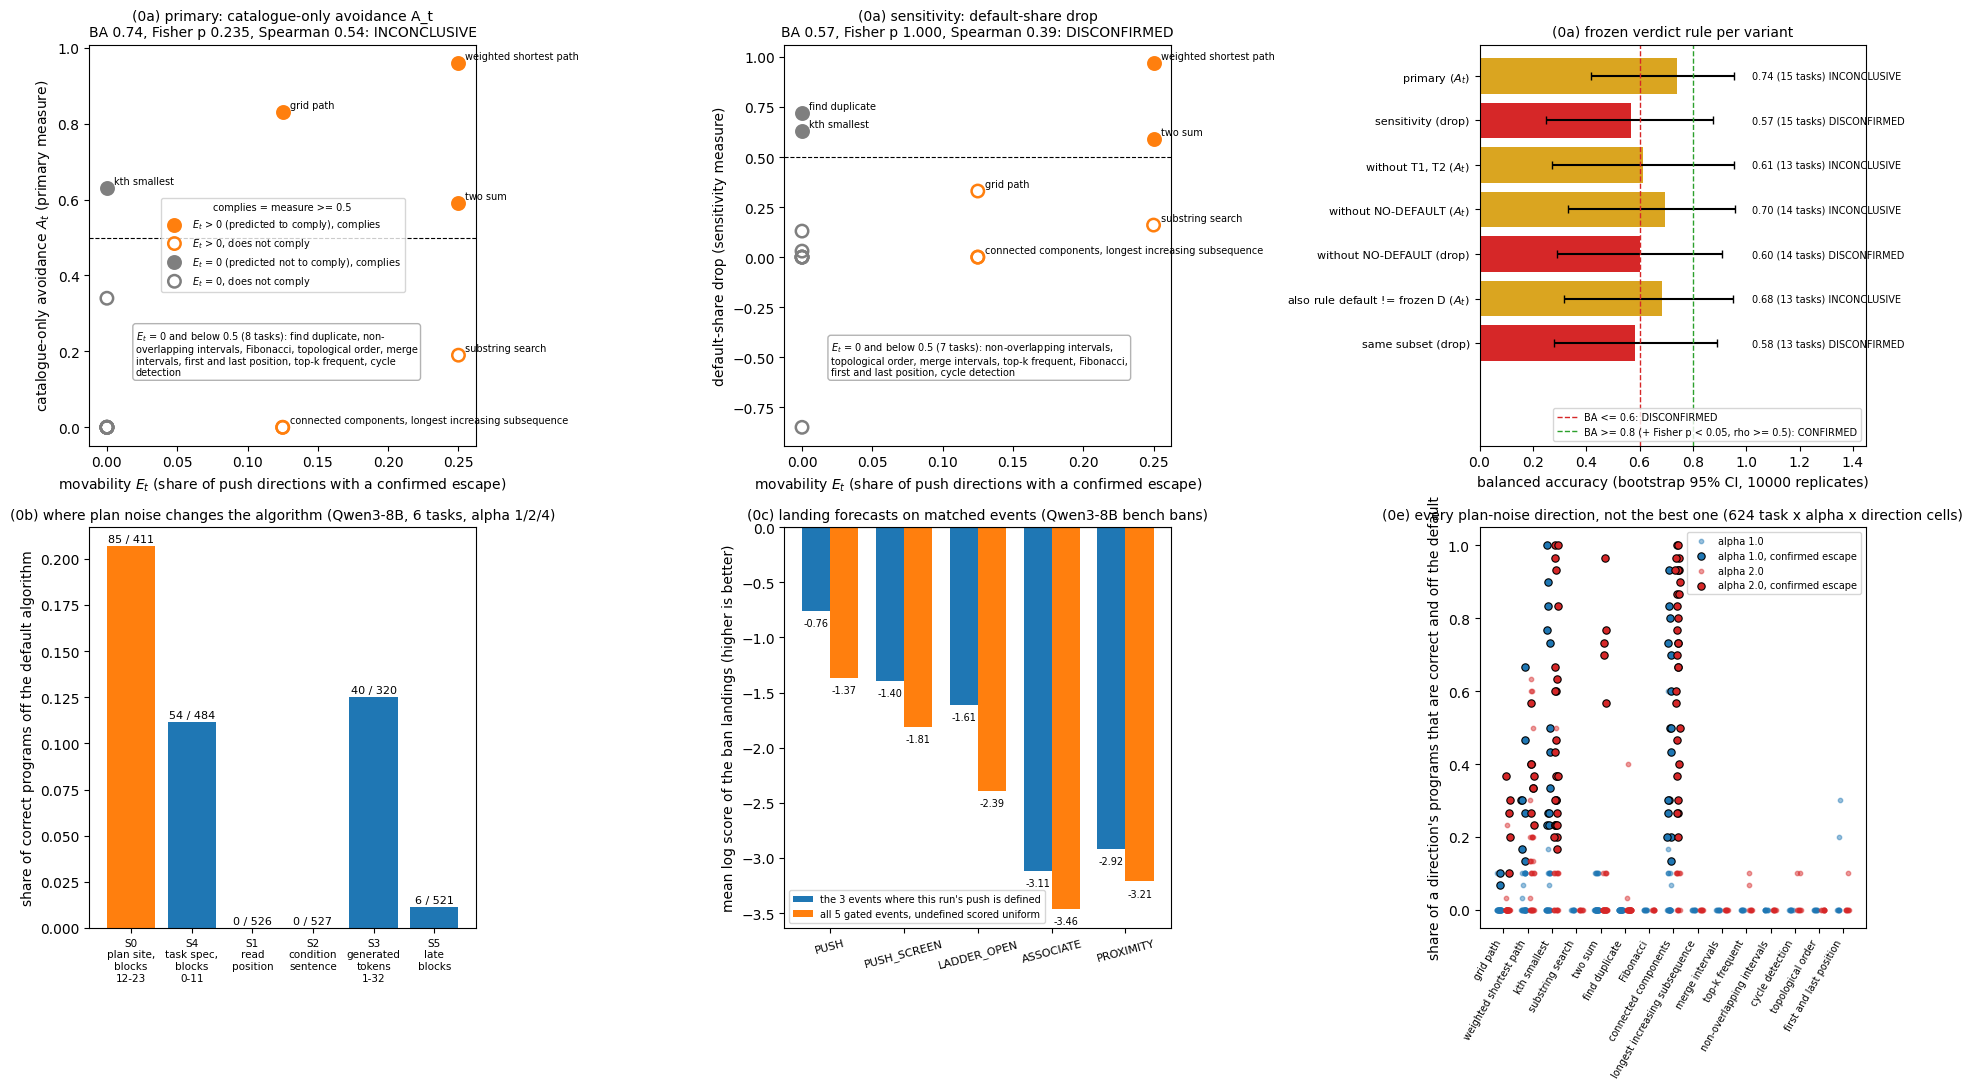

In [20]:
import textwrap

pt = METRICS["0a"]["per_task"]
vs = METRICS["0a"]["variants"]
fig, axs = plt.subplots(2, 3, figsize=(19, 11))

# (a), (b) the held-out test, one point per Gemma task: movability E_t (prediction) against compliance (outcome)
for ax, key, v, ylab in ((axs[0, 0], "A_catalogue_only", vs[0], "catalogue-only avoidance $A_t$ (primary measure)"),
                         (axs[0, 1], "default_share_drop", vs[1], "default-share drop (sensitivity measure)")):
    spots = defaultdict(list)  # tasks at the same coordinates share one label
    for t, row in pt.items():
        e, y = row["E_t"], row[key]
        col = "tab:orange" if e > 0 else "tab:gray"
        ax.scatter(e, y, s=80, facecolors=col if y >= 0.5 else "none", edgecolors=col, linewidths=1.8, zorder=3)
        spots[(round(e, 3), round(y, 3))].append(t)
    quiet = []  # E_t = 0 and below 0.5 (correctly predicted not to comply): listed in a box, not labelled one by one
    for (e, y), ts in spots.items():
        if e == 0 and y < 0.5:
            quiet += ts
        else:
            ax.annotate(", ".join(NAMES[t] for t in ts), (e, y), xytext=(5, 3), textcoords="offset points", fontsize=7)
    ax.text(0.12, 0.17, textwrap.fill(f"$E_t$ = 0 and below 0.5 ({len(quiet)} tasks): " +
                                      ", ".join(NAMES[t] for t in quiet), 62),
            transform=ax.transAxes, fontsize=7, va="bottom", bbox=dict(boxstyle="round", fc="w", ec="0.7"))
    ax.axhline(0.5, ls="--", c="k", lw=0.8)
    ax.set_xlabel("movability $E_t$ (share of push directions with a confirmed escape)")
    ax.set_ylabel(ylab)
    ax.set_title(f"(0a) {v['variant']}\nBA {fmt(v['BA'])}, Fisher p {fmt(v['fisher_p_two_sided'], 3)}, "
                 f"Spearman {fmt(v['spearman_rho'])}: {v['verdict_frozen_rule']}", fontsize=10)
for fc, ec, lab in (("tab:orange", "tab:orange", "$E_t$ > 0 (predicted to comply), complies"),
                    ("none", "tab:orange", "$E_t$ > 0, does not comply"),
                    ("tab:gray", "tab:gray", "$E_t$ = 0 (predicted not to comply), complies"),
                    ("none", "tab:gray", "$E_t$ = 0, does not comply")):
    axs[0, 0].scatter([], [], s=80, facecolors=fc, edgecolors=ec, linewidths=1.8, label=lab)
axs[0, 0].legend(fontsize=7, loc="center", title="complies = measure >= 0.5", title_fontsize=7)

# (c) balanced accuracy of every (0a) variant against the frozen verdict thresholds
ax = axs[0, 2]
short = {"primary: catalogue-only avoidance A_t": "primary ($A_t$)",
         "sensitivity: default-share drop": "sensitivity (drop)",
         "without T1 and T2 (A_t)": "without T1, T2 ($A_t$)",
         "descriptive: without NO-DEFAULT tasks (A_t)": "without NO-DEFAULT ($A_t$)",
         "descriptive: without NO-DEFAULT tasks (drop)": "without NO-DEFAULT (drop)",
         "descriptive: without NO-DEFAULT tasks and tasks whose rule default != frozen D (A_t)":
             "also rule default != frozen D ($A_t$)",
         "descriptive: same subset (drop)": "same subset (drop)"}
vcol = {"CONFIRMED": "tab:green", "INCONCLUSIVE": "goldenrod", "DISCONFIRMED": "tab:red"}
yy = np.arange(len(vs))
ba = np.array([np.nan if v["BA"] is None else v["BA"] for v in vs])
err = np.clip(np.array([[b - v["BA_ci95"][0], v["BA_ci95"][1] - b] if v["BA_ci95"] and v["BA"] is not None else [0, 0]
                        for b, v in zip(ba, vs)]).T, 0, None)
ax.barh(yy, ba, xerr=err, capsize=3, color=[vcol.get(v["verdict_frozen_rule"], "tab:gray") for v in vs])
for y_, v in zip(yy, vs):
    ax.annotate(f"{fmt(v['BA'])} ({v['n_tasks']} tasks) {v['verdict_frozen_rule']}", (1.02, y_), va="center", fontsize=7)
ax.axvline(0.6, ls="--", c="tab:red", lw=1, label="BA <= 0.6: DISCONFIRMED")
ax.axvline(0.8, ls="--", c="tab:green", lw=1, label="BA >= 0.8 (+ Fisher p < 0.05, rho >= 0.5): CONFIRMED")
ax.set_yticks(yy, [short.get(v["variant"], v["variant"][:30]) for v in vs], fontsize=8)
ax.set_ylim(len(vs) + 1.3, -0.7)  # inverted y axis, with free rows at the bottom for the legend
ax.set_xlim(0, 1.45)
ax.set_xlabel(f"balanced accuracy (bootstrap 95% CI, {N_BOOT} replicates)")
ax.set_title("(0a) frozen verdict rule per variant", fontsize=10)
ax.legend(fontsize=7, loc="lower right")

# (d) which prefill site changes the algorithm
ax = axs[1, 0]
sc = METRICS["0b"]["site_counts"]
order = ["S0", "S4", "S1", "S2", "S3", "S5"]
desc = {"S0": "S0\nplan site,\nblocks\n12-23", "S4": "S4\ntask spec,\nblocks\n0-11", "S1": "S1\nread\nposition",
        "S2": "S2\ncondition\nsentence", "S3": "S3\ngenerated\ntokens\n1-32", "S5": "S5\nlate\nblocks"}
share = [sc[s]["n_correct_off_default"] / sc[s]["n_correct"] if sc[s]["n_correct"] else 0.0 for s in order]
ax.bar(range(len(order)), share, color=["tab:orange" if s == "S0" else "tab:blue" for s in order])
for i, s in enumerate(order):
    ax.annotate(f"{sc[s]['n_correct_off_default']} / {sc[s]['n_correct']}", (i, share[i]), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=8)
ax.set_xticks(range(len(order)), [desc[s] for s in order], fontsize=7.5)
ax.set_ylabel("share of correct programs off the default algorithm")
ax.set_title("(0b) where plan noise changes the algorithm (Qwen3-8B, 6 tasks, alpha 1/2/4)", fontsize=10)

# (e) landing forecasts scored on matched event sets
ax = axs[1, 1]
rows_ = METRICS["0c"]["table"]
x = np.arange(len(rows_))
w = 0.38
for dx, key, lab in ((-w / 2, "mean_bench_push_defined", "the 3 events where this run's push is defined"),
                     (w / 2, "mean_bench_all_gated_uniform_fill", "all 5 gated events, undefined scored uniform")):
    hv = np.array([np.nan if row[key] is None else row[key] for row in rows_])
    ax.bar(x + dx, hv, w, label=lab)
    for xi, h in zip(x + dx, hv):
        if not np.isnan(h):
            ax.annotate(f"{h:.2f}", (xi, h), xytext=(0, -11), textcoords="offset points", ha="center", fontsize=7)
ax.set_xticks(x, [row["forecast"] for row in rows_], rotation=15, fontsize=8)
ax.axhline(0, c="k", lw=0.8)
ax.set_ylabel("mean log score of the ban landings (higher is better)")
ax.set_title("(0c) landing forecasts on matched events (Qwen3-8B bench bans)", fontsize=10)
ax.legend(fontsize=7, loc="lower left")

# (f) every random direction, not only the best one
ax = axs[1, 2]
with (TABLES / "direction_distributions.csv").open() as fh:
    dd = list(csv.DictReader(fh))
tl = [t for t in TASKS if any(r_["task"] == t for r_ in dd)]
jit = np.random.default_rng(0)
for i, t in enumerate(tl):
    for a, col, dx in (("1.0", "tab:blue", -0.17), ("2.0", "tab:red", 0.17)):
        cl = [r_ for r_ in dd if r_["task"] == t and r_["alpha"] == a]
        ys = np.array([float(r_["correct_off_default_share"]) for r_ in cl])
        es = np.array([r_["escape_confirmed"] == "True" for r_ in cl], dtype=bool)
        xs = i + dx + jit.uniform(-0.09, 0.09, len(ys))
        ax.scatter(xs[~es], ys[~es], s=10, color=col, alpha=0.45, label=f"alpha {a}" if i == 0 else None)
        ax.scatter(xs[es], ys[es], s=28, color=col, edgecolors="k", linewidths=0.8,
                   label=f"alpha {a}, confirmed escape" if i == 0 else None)
ax.set_xticks(range(len(tl)), [NAMES[t] for t in tl], rotation=60, ha="right", fontsize=7)
ax.set_ylabel("share of a direction's programs that are correct and off the default")
ax.set_title(f"(0e) every plan-noise direction, not the best one ({len(dd)} task x alpha x direction cells)", fontsize=10)
ax.legend(fontsize=7, loc="upper right")

plt.tight_layout()
fig.savefig(WS / "summary.png", dpi=110)
plt.show()